# Proyecto AD3010 — Caso D: Volatilidad de insumos
**Cliente:** cadena de restaurantes de menú criollo en Lima (8 locales).
**Decisión:** qué insumos priorizar, cuándo comprarlos y cuánto ajustar el precio de carta.

**Fuentes (data ampliada):**
1. **SISAP (MIDAGRI)** — precio mayorista diario, Gran Mercado Mayorista de Lima, **ago-2020 a ago-2026** (dataset base, 6 años).
2. **INEI** — precio minorista promedio mensual, Lima Metropolitana, **ago-2020 a ago-2026** (enriquecimiento Vía 2).
3. **Relevamiento propio** — **147 precios** por establecimiento en Surquillo, Miraflores y Barranco, 7–16 sep 2026, al menos 9 por insumo (enriquecimiento Vía 1).


## 0. Configuración y carga de datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_percentage_error,
                             accuracy_score, precision_score, recall_score, confusion_matrix,
                             silhouette_score)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

ARCHIVO_SISAP = "sisap_ampliado.csv"
ARCHIVO_INEI = "inei_ampliado.csv"
ARCHIVO_RELEV = "relevamiento_ampliado.csv"

faltan = [f for f in [ARCHIVO_SISAP, ARCHIVO_INEI, ARCHIVO_RELEV] if not os.path.exists(f)]
if faltan:
    try:
        from google.colab import files
        print("Faltan estos archivos, súbelos:", faltan)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"No se encuentran: {faltan}")

# Los 6 insumos priorizados en la PC1
SEIS = ["zanahoria", "ajo", "poro", "camote_amarillo", "olluco", "limon"]

## 1. Preparación y cruces
### 1.1 SISAP: normalizar a soles/kg y crear la llave común `insumo_estandar`
SISAP reporta algunos insumos por atado, bolsa o saco. INEI siempre está en soles/kg,
así que dividimos `precio_hoy` entre `equiv_kg` para que ambos estén en la misma unidad.

In [2]:
df = pd.read_csv(ARCHIVO_SISAP, encoding="utf-8-sig")
df["fecha"] = pd.to_datetime(df["fecha"])
print(f"SISAP crudo: {df.shape[0]:,} filas, {df.shape[1]} columnas, {df['producto'].nunique()} productos")
print(f"Período: {df['fecha'].min().date()} a {df['fecha'].max().date()}")

duplicados = df.duplicated(["fecha", "producto"]).sum()
df = df.drop_duplicates(["fecha", "producto"])
print(f"Duplicados fecha+producto eliminados: {duplicados}")

df["precio_soles_kg"] = df["precio_hoy"] / df["equiv_kg"]

insumo_estandar = {
    "AJO CRIOLLO O NAPURI": "ajo", "APIO": "apio", "CAMOTE AMARILLO": "camote_amarillo",
    "CEBOLLA CABEZA ROJA": "cebolla_roja", "CEBOLLA CHINA": "cebolla_china", "ESPINACA": "espinaca",
    "LIMON SUTIL BOLSA": "limon", "MAIZ MORADO": "maiz_morado", "OLLUCO LARGO": "olluco",
    "PAPA AMARILLA": "papa_amarilla", "PAPA BLANCA": "papa_blanca", "PAPA HUAYRO": "papa_huayro",
    "PORO": "poro", "VAINITA AMERICANA": "vainita", "ZANAHORIA": "zanahoria",
    "ZAPALLO MACRE": "zapallo_macre",
}
sisap16 = df[df["producto"].isin(insumo_estandar.keys())].copy()
sisap16["insumo_estandar"] = sisap16["producto"].map(insumo_estandar)
sisap16["año_mes"] = sisap16["fecha"].dt.to_period("M").astype(str)

print(f"\nSISAP filtrado a 16 insumos: {len(sisap16):,} filas")
print("Insumos convertidos con equiv_kg (no venían en kg):")
print(sisap16.loc[sisap16["equiv_kg"] != 1, ["producto", "unidad_medida", "equiv_kg"]].drop_duplicates().to_string(index=False))

SISAP crudo: 65,888 filas, 7 columnas, 78 productos
Período: 2020-08-03 a 2026-08-05
Duplicados fecha+producto eliminados: 1

SISAP filtrado a 16 insumos: 24,260 filas
Insumos convertidos con equiv_kg (no venían en kg):
         producto unidad_medida  equiv_kg
             APIO         ATADO      3.00
LIMON SUTIL BOLSA         BOLSA     45.00
             PORO         ATADO      2.60
        ZANAHORIA    SACO CHICO     65.00


### 1.2 INEI: misma llave `insumo_estandar`

In [3]:
inei = pd.read_csv(ARCHIVO_INEI, encoding="utf-8-sig")
insumo_estandar_inei = {
    "AJO ENTERO": "ajo", "APIO": "apio", "CAMOTE AMARILLO": "camote_amarillo",
    "CEBOLLA CABEZA": "cebolla_roja", "CEBOLLA CHINA": "cebolla_china", "ESPINACA": "espinaca",
    "LIMON": "limon", "MAIZ MORADO": "maiz_morado", "OLLUCO LARGO": "olluco",
    "PAPA AMARILLA": "papa_amarilla", "PAPA BLANCA": "papa_blanca", "PAPA HUAYRO": "papa_huayro",
    "PORO": "poro", "VAINITA AMERICANA": "vainita", "ZANAHORIA": "zanahoria",
    "ZAPALLO MACRE": "zapallo_macre",
}
inei["insumo_estandar"] = inei["producto_inei"].map(insumo_estandar_inei)
inei = inei.rename(columns={"precio_soles": "precio_minorista_inei"})
print(f"INEI: {inei.shape[0]} filas | meses: {inei['año_mes'].min()} a {inei['año_mes'].max()}")
print(f"Productos INEI sin mapear: {inei['insumo_estandar'].isna().sum()}")

INEI: 1168 filas | meses: 2020-08 a 2026-08
Productos INEI sin mapear: 0


### 1.3 Cruce SISAP + INEI — bitácora de cruce
**Llave:** `insumo_estandar` + `año_mes`. SISAP es diario e INEI mensual, así que cada día de SISAP
recibe el precio minorista de su mes.

**Dos medidas de la diferencia de precio:**
- `brecha_pct` = (INEI − SISAP) / SISAP × 100 → cuánto se infla el precio sobre el mayorista (usada en nuestra PC1).
- `mbc_pct` = (INEI − SISAP) / INEI × 100 → **Margen Bruto de Comercialización (KPI2)**: qué parte del precio final se queda en la cadena.

In [4]:
filas_antes = len(sisap16)
panel = sisap16.merge(inei[["insumo_estandar", "año_mes", "precio_minorista_inei"]],
                      on=["insumo_estandar", "año_mes"], how="left")
panel["brecha_soles_kg"] = panel["precio_minorista_inei"] - panel["precio_soles_kg"]
panel["brecha_pct"] = panel["brecha_soles_kg"] / panel["precio_soles_kg"] * 100
panel["mbc_pct"] = panel["brecha_soles_kg"] / panel["precio_minorista_inei"] * 100

print("BITÁCORA DE CRUCE SISAP + INEI")
print(f"  Filas antes del merge:  {filas_antes:,}")
print(f"  Filas después:          {len(panel):,}")
print(f"  Nulos generados:        {panel['precio_minorista_inei'].isna().sum():,}")
print(f"  Tasa de cruce:          {panel['precio_minorista_inei'].notna().mean()*100:.1f}%")
print("  Decisión: no hay registros sin cruzar, no se descarta nada.")

BITÁCORA DE CRUCE SISAP + INEI
  Filas antes del merge:  24,260
  Filas después:          24,260
  Nulos generados:        0
  Tasa de cruce:          100.0%
  Decisión: no hay registros sin cruzar, no se descarta nada.


### 1.4 Relevamiento propio — bitácora de cruce
El relevamiento es de septiembre 2026, pero SISAP llega hasta el 5 de agosto 2026. No hay mismo día para cruzar.

**Decisión:** comparamos cada precio relevado contra el **promedio mayorista de los últimos 30 días disponibles**
en SISAP (6 jul – 5 ago 2026). Usamos el promedio de 30 días y no un solo día porque un solo día puede
ser un pico o una caída puntual. Esta diferencia de fechas se reporta como limitación.

In [5]:
relev = pd.read_csv(ARCHIVO_RELEV, encoding="utf-8-sig")
relev["fecha"] = pd.to_datetime(relev["fecha"])
print(f"Relevamiento: {len(relev)} observaciones válidas | {relev['fecha'].min().date()} a {relev['fecha'].max().date()}")
print(f"  {relev['establecimiento'].nunique()} establecimientos, {relev['distrito'].nunique()} distritos, "
      f"{relev['fecha'].nunique()} días distintos, {relev['insumo_estandar'].nunique()} insumos")
print(relev.groupby("distrito").size().rename("observaciones").to_string())

fin_sisap = sisap16["fecha"].max()
ref_mayorista = (sisap16[sisap16["fecha"] > fin_sisap - pd.Timedelta(days=30)]
                 .groupby("insumo_estandar")["precio_soles_kg"].mean()
                 .rename("precio_mayorista_ref").reset_index())
ref_inei_ago = (inei[inei["año_mes"] == inei["año_mes"].max()][["insumo_estandar", "precio_minorista_inei"]]
                .rename(columns={"precio_minorista_inei": "precio_inei_ultimo_mes"}))

filas_antes = len(relev)
relev = relev.merge(ref_mayorista, on="insumo_estandar", how="left").merge(ref_inei_ago, on="insumo_estandar", how="left")
relev["dias_de_diferencia"] = (relev["fecha"] - fin_sisap).dt.days
relev["brecha_vs_mayorista_pct"] = (relev["precio_soles"] / relev["precio_mayorista_ref"] - 1) * 100
relev["indice_vs_mayorista"] = relev["precio_soles"] / relev["precio_mayorista_ref"]

print("\nBITÁCORA DE CRUCE RELEVAMIENTO + SISAP + INEI")
print(f"  Filas antes: {filas_antes} | después: {len(relev)}")
print(f"  Tasa de cruce con SISAP: {relev['precio_mayorista_ref'].notna().mean()*100:.0f}% | "
      f"con INEI: {relev['precio_inei_ultimo_mes'].notna().mean()*100:.0f}%")
print(f"  Días entre fin de SISAP y el relevamiento: {relev['dias_de_diferencia'].min()} a {relev['dias_de_diferencia'].max()}")

Relevamiento: 147 observaciones válidas | 2026-09-07 a 2026-09-16
  26 establecimientos, 3 distritos, 10 días distintos, 16 insumos
distrito
Barranco      48
Miraflores    50
Surquillo     49

BITÁCORA DE CRUCE RELEVAMIENTO + SISAP + INEI
  Filas antes: 147 | después: 147
  Tasa de cruce con SISAP: 100% | con INEI: 100%
  Días entre fin de SISAP y el relevamiento: 33 a 42


**Limitación documentada:** el relevamiento (7–16 sep 2026) se compara contra SISAP de 6 jul – 5 ago 2026,
es decir, con 33 a 42 días de diferencia, porque el dataset base no llega a septiembre.

## 2. Selección de los 6 insumos priorizados
Se recalcula el criterio de la PC1: `riesgo_score` = ranking de brecha promedio + ranking de variabilidad de la brecha.

In [6]:
resumen_brecha = panel.groupby("insumo_estandar")["brecha_pct"].agg(brecha_media="mean", brecha_std="std").reset_index()
resumen_brecha["rank_brecha"] = resumen_brecha["brecha_media"].rank(ascending=False)
resumen_brecha["rank_volatilidad"] = resumen_brecha["brecha_std"].rank(ascending=False)
resumen_brecha["riesgo_score"] = resumen_brecha["rank_brecha"] + resumen_brecha["rank_volatilidad"]
resumen_brecha = resumen_brecha.sort_values("riesgo_score")
print("Top 6 por riesgo_score:", resumen_brecha.head(6)["insumo_estandar"].tolist())
print("Lista usada (PC1):     ", SEIS)
resumen_brecha

Top 6 por riesgo_score: ['zanahoria', 'camote_amarillo', 'olluco', 'poro', 'ajo', 'vainita']
Lista usada (PC1):      ['zanahoria', 'ajo', 'poro', 'camote_amarillo', 'olluco', 'limon']


,insumo_estandar,brecha_media,brecha_std,rank_brecha,rank_volatilidad,riesgo_score
14,zanahoria,245.33,95.71,1.00,2.00,3.00
2,camote_amarillo,197.28,95.45,3.00,3.00,6.00
8,olluco,194.52,99.73,5.00,1.00,6.00
12,poro,221.05,77.64,2.00,5.00,7.00
0,ajo,196.00,91.44,4.00,4.00,8.00
13,vainita,151.80,74.81,8.00,7.00,15.00
5,espinaca,170.55,71.36,7.00,8.00,15.00
4,cebolla_roja,138.81,77.23,10.00,6.00,16.00
6,limon,187.97,66.59,6.00,10.00,16.00
10,papa_blanca,149.87,54.64,9.00,12.00,21.00


**Decisión:** con 6 años de datos, el top 6 por `riesgo_score` cambia levemente: entra **vainita** y sale **limón**.
Mantenemos la lista de la PC1 (con limón) por tres razones:
1. El limón es el insumo **más volátil** de los 16 (KPI1, sección 4).
2. Es casi la **mitad del costo de verduras del cebiche** (sección 12), el plato bandera de un restaurante criollo.
3. Mantener la lista permite comparar contra la PC1. La vainita queda cubierta en el análisis de los 16 insumos (KPIs, clustering, costo por plato).

## 3. EDA (6 insumos priorizados)
Esta sección deja corriendo el EDA de la PC1 con dos correcciones:
- Se define `marcar_outliers` (antes faltaba y la celda daba error).
- El boxplot por distrito ahora usa precio relativo al mayorista. Antes comparaba precios crudos mezclando
  insumos distintos en cada distrito (un kilo de ajo no se compara con un kilo de zanahoria).

In [7]:
sisap6 = sisap16[sisap16["insumo_estandar"].isin(SEIS)].copy()
inei6 = inei[inei["insumo_estandar"].isin(SEIS)].copy()

print("Nulos en SISAP (6 insumos):", int(sisap6.isna().sum().sum()), "| en INEI:", int(inei6.isna().sum().sum()))
sisap6.groupby("insumo_estandar")["precio_soles_kg"].describe()

Nulos en SISAP (6 insumos): 0 | en INEI: 0


,count,mean,std,min,25%,50%,75%,max
insumo_estandar,,,,,,,,
ajo,"1,517.00",7.67,4.42,2.53,5.35,6.61,8.38,36.50
camote_amarillo,"1,517.00",1.00,0.53,0.35,0.59,0.88,1.20,3.28
limon,"1,517.00",2.06,1.40,0.94,1.37,1.67,2.20,12.11
olluco,"1,517.00",2.32,1.17,0.91,1.36,2.01,2.83,6.33
poro,"1,517.00",1.71,0.58,0.73,1.30,1.63,2.10,3.65
zanahoria,"1,517.00",0.89,0.31,0.33,0.67,0.83,1.07,2.15


In [8]:
def marcar_outliers(serie):
    """True si el precio está fuera de 1.5 veces el rango intercuartílico de su insumo."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

sisap6["es_outlier"] = sisap6.groupby("insumo_estandar")["precio_soles_kg"].transform(marcar_outliers)
print("Días atípicos por insumo (se mantienen: son shocks reales de oferta, no errores):")
sisap6.groupby("insumo_estandar")["es_outlier"].agg(dias_atipicos="sum", pct=lambda s: s.mean() * 100).sort_values("dias_atipicos", ascending=False)

Días atípicos por insumo (se mantienen: son shocks reales de oferta, no errores):


,dias_atipicos,pct
insumo_estandar,,
ajo,117,7.71
limon,111,7.32
camote_amarillo,91,6.00
olluco,77,5.08
zanahoria,26,1.71
poro,15,0.99


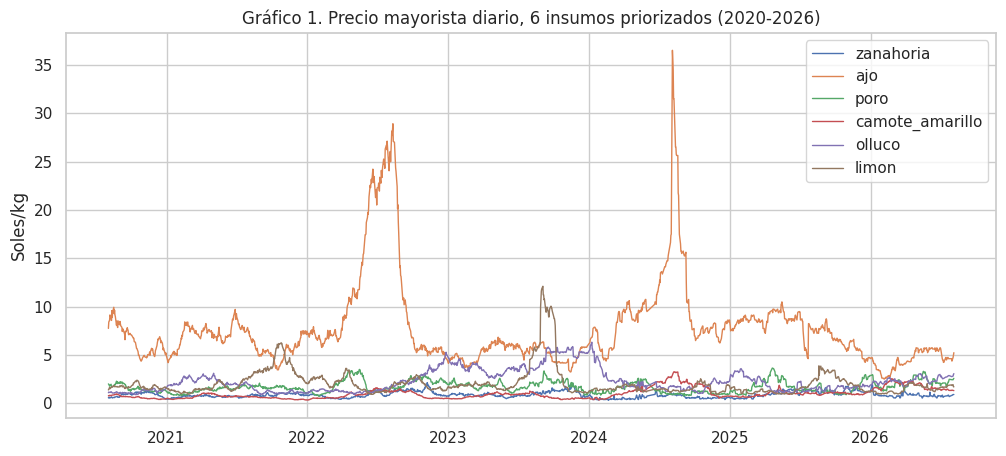

In [9]:
# Gráfico 1 — Serie de tiempo del precio mayorista
plt.figure(figsize=(12, 5))
for insumo in SEIS:
    d = sisap6[sisap6["insumo_estandar"] == insumo]
    plt.plot(d["fecha"], d["precio_soles_kg"], label=insumo, linewidth=1)
plt.legend(); plt.ylabel("Soles/kg")
plt.title("Gráfico 1. Precio mayorista diario, 6 insumos priorizados (2020-2026)")
plt.show()

**Lectura (Gráfico 1):** con 6 años se ve que el ajo tuvo **dos** shocks fuertes: uno en 2022 (~S/ 19 por kg en promedio trimestral)
y otro mayor en 2024 (llegó a más de S/ 36 por kg en un día). No es un evento aislado: el ajo tiene alzas fuertes cada 2 años aprox.
El limón tiene su pico en septiembre 2023 (El Niño costero). Los demás se mueven en rangos mucho más chicos en soles.

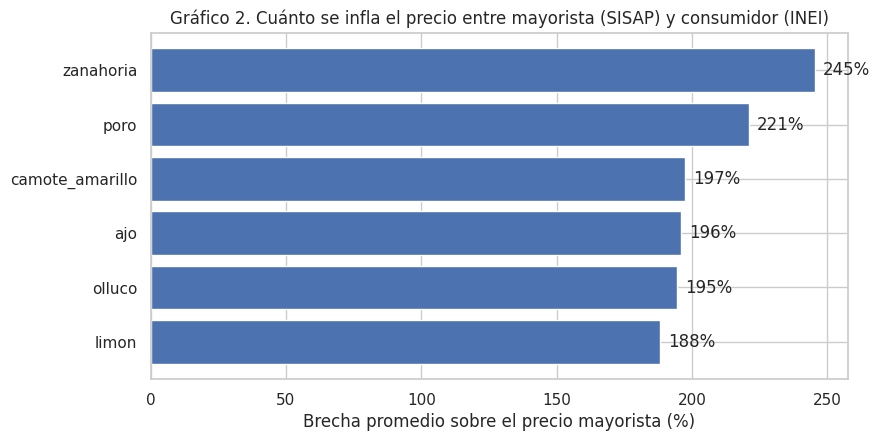

In [10]:
# Gráfico 2 — Brecha mayorista-minorista histórica
orden = resumen_brecha[resumen_brecha["insumo_estandar"].isin(SEIS)].sort_values("brecha_media")
plt.figure(figsize=(9, 4.5))
plt.barh(orden["insumo_estandar"], orden["brecha_media"], color="#4C72B0")
for y, v in enumerate(orden["brecha_media"]):
    plt.text(v + 3, y, f"{v:.0f}%", va="center")
plt.xlabel("Brecha promedio sobre el precio mayorista (%)")
plt.title("Gráfico 2. Cuánto se infla el precio entre mayorista (SISAP) y consumidor (INEI)")
plt.show()

**Lectura (Gráfico 2):** zanahoria (245%) y poro (221%) son los que más se inflan entre el mercado mayorista y el consumidor.
Para el restaurante, son los insumos donde comprar directo en el mayorista ahorra más frente a comprar en un mercado minorista.

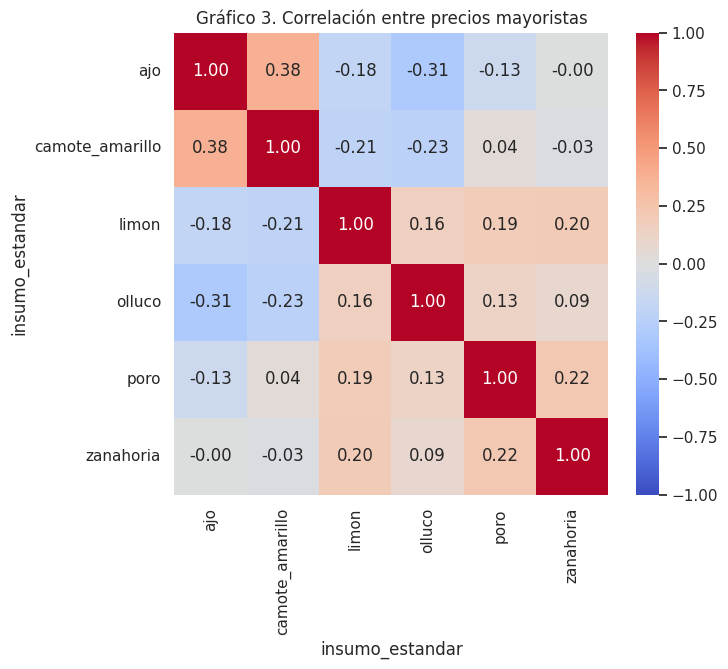

In [11]:
# Gráfico 3 — Correlación entre precios mayoristas
correlacion6 = sisap6.pivot_table(index="fecha", columns="insumo_estandar", values="precio_soles_kg").corr()
plt.figure(figsize=(7, 6))
sns.heatmap(correlacion6, cmap="coolwarm", center=0, annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.title("Gráfico 3. Correlación entre precios mayoristas")
plt.show()

**Lectura (Gráfico 3):** las correlaciones entre insumos son débiles o moderadas, y algunas negativas. El riesgo de precio
**no está concentrado**: cuando el ajo se dispara, no arrastra a los demás. Diversificar la carta entre estos insumos amortigua el riesgo total.

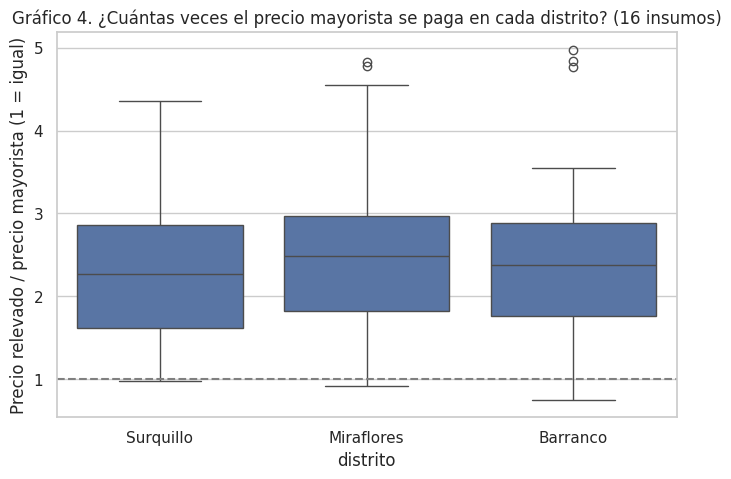

            median  mean  min  max  count
distrito                                 
Barranco      2.38  2.39 0.75 4.97     48
Miraflores    2.49  2.51 0.91 4.83     50
Surquillo     2.27  2.30 0.98 4.35     49


In [12]:
# Gráfico 4 — Precio relativo al mayorista por distrito (relevamiento propio)
plt.figure(figsize=(8, 5))
sns.boxplot(data=relev, x="distrito", y="indice_vs_mayorista", order=["Surquillo", "Miraflores", "Barranco"])
plt.axhline(1, color="gray", linestyle="--")
plt.ylabel("Precio relevado / precio mayorista (1 = igual)")
plt.title("Gráfico 4. ¿Cuántas veces el precio mayorista se paga en cada distrito? (16 insumos)")
plt.show()
print(relev.groupby("distrito")["indice_vs_mayorista"].agg(["median", "mean", "min", "max", "count"]))

**Lectura (Gráfico 4):** el valor 1 es "pagar lo mismo que en el mayorista". La mediana en **Surquillo es 2.3 veces** el precio
mayorista, en **Barranco 2.4 veces** y en **Miraflores 2.5 veces**.
**Cambio respecto de la versión con 60 precios:** antes Barranco parecía mucho más caro (2.7 veces). Con 147 precios, las diferencias entre
distritos se achican: **el distrito importa poco; lo que importa es comprar en el mayorista o no**. Surquillo sigue siendo el más barato.

## 4. PA1 — Volatilidad: ¿qué insumos requieren compra anticipada?
**KPI1:** Coeficiente de Variación (CV = desviación estándar / media) del precio mayorista diario, 2020-2026.
El CV permite comparar insumos de precio muy distinto: un CV de 30% significa que el precio
típicamente se aleja 30% de su promedio. Los insumos en el **tercio superior de CV** son candidatos a compra anticipada.

In [13]:
kpi1 = (sisap16.groupby("insumo_estandar")["precio_soles_kg"]
        .agg(precio_medio="mean", desviacion="std", minimo="min", maximo="max").reset_index())
kpi1["cv_pct"] = kpi1["desviacion"] / kpi1["precio_medio"] * 100
corte_cv = kpi1["cv_pct"].quantile(2 / 3)
kpi1["recomendacion_compra"] = np.where(kpi1["cv_pct"] >= corte_cv, "Candidato a compra anticipada", "Compra al día")
kpi1 = kpi1.sort_values("cv_pct", ascending=False).reset_index(drop=True)
print(f"Corte del tercio superior: CV >= {corte_cv:.1f}%")
kpi1

Corte del tercio superior: CV >= 44.1%


,insumo_estandar,precio_medio,desviacion,minimo,maximo,cv_pct,recomendacion_compra
0,limon,2.06,1.40,0.94,12.11,67.98,Candidato a compra anticipada
1,ajo,7.67,4.42,2.53,36.50,57.59,Candidato a compra anticipada
2,camote_amarillo,1.00,0.53,0.35,3.28,53.51,Candidato a compra anticipada
3,olluco,2.32,1.17,0.91,6.33,50.58,Candidato a compra anticipada
4,cebolla_roja,1.70,0.84,0.29,6.25,49.51,Candidato a compra anticipada
5,apio,2.58,1.13,0.65,7.00,44.05,Candidato a compra anticipada
6,cebolla_china,2.93,1.29,1.03,7.76,43.87,Compra al día
7,vainita,2.69,0.97,0.90,6.88,36.08,Compra al día
8,zanahoria,0.89,0.31,0.33,2.15,34.30,Compra al día
9,poro,1.71,0.58,0.73,3.65,33.92,Compra al día


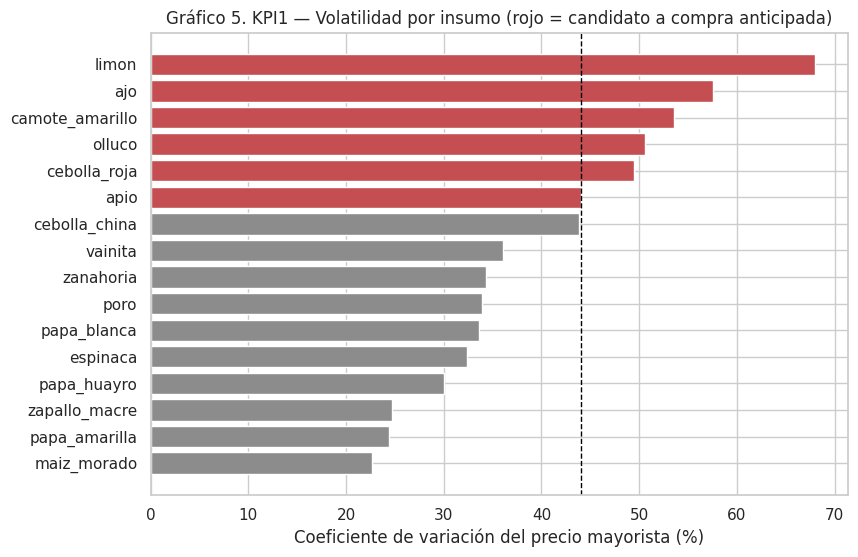

In [14]:
plt.figure(figsize=(9, 6))
colores = ["#C44E52" if r == "Candidato a compra anticipada" else "#8C8C8C" for r in kpi1["recomendacion_compra"]]
plt.barh(kpi1["insumo_estandar"], kpi1["cv_pct"], color=colores)
plt.axvline(corte_cv, color="black", linestyle="--", linewidth=1)
plt.gca().invert_yaxis()
plt.xlabel("Coeficiente de variación del precio mayorista (%)")
plt.title("Gráfico 5. KPI1 — Volatilidad por insumo (rojo = candidato a compra anticipada)")
plt.show()

**Lectura (KPI1) — respuesta a PA1:** el **limón** es el más volátil (CV 68%: llegó a S/ 12 por kg contra un promedio de S/ 2). Le siguen
ajo (58%), camote (54%), olluco (51%), cebolla roja (50%) y apio (44%). Son los **mismos seis** de la versión con 3 años: el resultado es robusto.
Según el criterio declarado en la PC1 (tercio superior de CV), estos seis son **candidatos a compra anticipada**.


## 5. PA2 — Margen de comercialización mayorista → minorista
**KPI2:** MBC = (precio INEI − precio SISAP) / precio INEI × 100, **mes a mes**.
Se usa el promedio mensual de SISAP para comparar en la misma frecuencia que INEI.

In [15]:
mensual = (sisap16.groupby(["insumo_estandar", "año_mes"])["precio_soles_kg"].mean()
           .rename("precio_mayorista_mes").reset_index()
           .merge(inei[["insumo_estandar", "año_mes", "precio_minorista_inei"]], on=["insumo_estandar", "año_mes"], how="left"))
mensual["mbc_pct"] = (mensual["precio_minorista_inei"] - mensual["precio_mayorista_mes"]) / mensual["precio_minorista_inei"] * 100
mensual["fecha_mes"] = pd.to_datetime(mensual["año_mes"])

kpi2 = mensual.groupby("insumo_estandar")["mbc_pct"].agg(mbc_medio="mean", mbc_std="std", mbc_min="min", mbc_max="max").reset_index()
kpi2 = kpi2.sort_values("mbc_medio", ascending=False).reset_index(drop=True)
kpi2

,insumo_estandar,mbc_medio,mbc_std,mbc_min,mbc_max
0,zanahoria,68.78,7.38,51.20,82.65
1,poro,66.97,7.14,46.60,78.78
2,limon,63.12,8.20,37.40,75.01
3,ajo,63.08,10.85,28.83,84.79
4,camote_amarillo,61.94,13.27,19.15,79.25
5,olluco,61.42,13.46,27.02,77.92
6,espinaca,60.37,8.15,39.22,75.53
7,papa_blanca,57.74,9.29,31.12,74.31
8,vainita,56.63,9.02,31.76,75.92
9,zapallo_macre,55.12,7.65,37.78,70.96


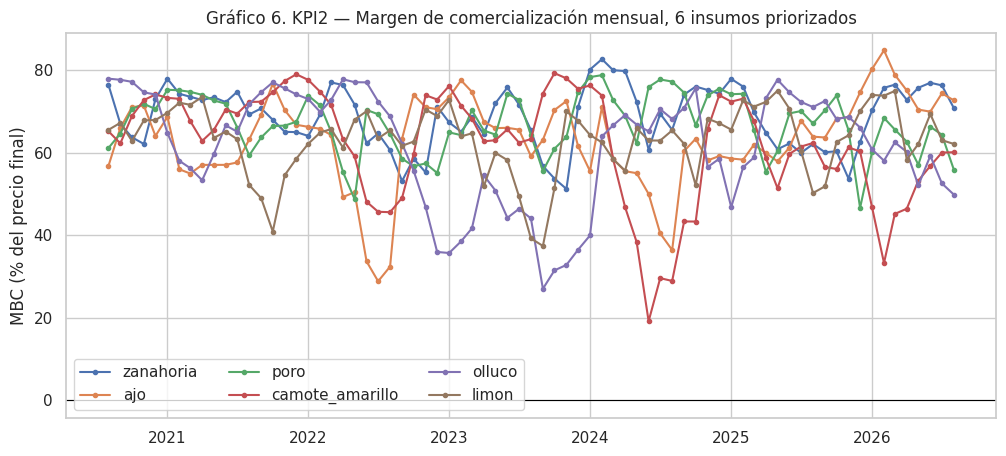

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
for insumo in SEIS:
    d = mensual[mensual["insumo_estandar"] == insumo]
    ax.plot(d["fecha_mes"], d["mbc_pct"], marker="o", markersize=3, label=insumo)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("MBC (% del precio final)")
ax.set_title("Gráfico 6. KPI2 — Margen de comercialización mensual, 6 insumos priorizados")
ax.legend(ncol=3)
plt.show()

**Lectura (KPI2):** en la **zanahoria**, de cada sol que paga el consumidor, **69 céntimos** se quedan en la cadena de comercialización;
en poro 67, en limón y ajo 63. En el otro extremo, el **apio** solo tiene 28% (y en algunos meses el minorista fue *más barato*
que el mayorista, MBC negativo; puede deberse a la equivalencia del atado de apio). Para el restaurante en los insumos
de MBC alto, comprar en el mayorista en vez de a un minorista recorta el costo a menos de la mitad.

## 6. Modelo supervisado — ¿cuánto costará cada insumo dentro de 4 semanas?
**Variable objetivo (del caso D):** precio mayorista del insumo a 4 semanas.

**Diseño:**
- Datos semanales de los 16 insumos (más datos = modelo más estable).
- En vez de predecir el precio en soles, el modelo predice el **cambio %** a 4 semanas. Así un insumo caro
  como el ajo no domina el modelo frente a uno barato como la zanahoria. Luego se convierte a soles.
- **Variables explicativas:**
  - `cambio_1sem`, `cambio_4sem`: cuánto subió o bajó el precio la última semana y el último mes (inercia).
  - `desvio_media_12sem`: qué tan lejos está el precio hoy de su promedio de 3 meses (¿está caro o barato?).
  - `log_brecha_inei`: **enriquecimiento INEI** — brecha minorista del mes anterior (solo meses ya publicados, para no usar el futuro),
    en escala logarítmica. El log hace que pasar de 100% a 200% de brecha pese parecido a pasar de 200% a 400%,
    y evita que valores extremos (como el ajo en 2026, con 290%) disparen el pronóstico.
  - Mes del año (estacionalidad) e insumo.
- **Entrenamiento:** oct-2020 a dic-2025 (más del doble de datos que la versión anterior). **Prueba:** ene a ago-2026 (datos que el modelo nunca vio).
- **Comparación honesta:** contra un pronóstico **ingenuo** ("en 4 semanas costará lo mismo que hoy") y contra el mismo modelo **sin INEI**.

In [17]:
semanal = (sisap16.set_index("fecha").groupby("insumo_estandar")["precio_soles_kg"]
           .resample("W-MON").mean().reset_index()
           .rename(columns={"precio_soles_kg": "precio"}))
semanal["precio"] = semanal.groupby("insumo_estandar")["precio"].transform(lambda s: s.interpolate(limit=2))
semanal = semanal.sort_values(["insumo_estandar", "fecha"]).reset_index(drop=True)

g = semanal.groupby("insumo_estandar")["precio"]
semanal["cambio_1sem"] = g.pct_change(1, fill_method=None) * 100
semanal["cambio_4sem"] = g.pct_change(4, fill_method=None) * 100
semanal["desvio_media_12sem"] = (semanal["precio"] / g.transform(lambda s: s.rolling(12).mean()) - 1) * 100
semanal["mes"] = semanal["fecha"].dt.month

# Enriquecimiento INEI: brecha del mes anterior
semanal["año_mes_ant"] = (semanal["fecha"].dt.to_period("M") - 1).astype(str)
brecha_mensual = mensual[["insumo_estandar", "año_mes", "precio_mayorista_mes", "precio_minorista_inei"]].copy()
brecha_mensual["brecha_inei_mes_ant"] = (brecha_mensual["precio_minorista_inei"] / brecha_mensual["precio_mayorista_mes"] - 1) * 100
semanal = semanal.merge(brecha_mensual[["insumo_estandar", "año_mes", "brecha_inei_mes_ant"]]
                        .rename(columns={"año_mes": "año_mes_ant"}), on=["insumo_estandar", "año_mes_ant"], how="left")
semanal["log_brecha_inei"] = np.log1p(semanal["brecha_inei_mes_ant"] / 100)
print(f"Semanas: {len(semanal):,} | con dato INEI del mes anterior: {semanal['brecha_inei_mes_ant'].notna().mean()*100:.1f}%")
print(f"(Las semanas sin dato son las del primer mes, {semanal['fecha'].min():%b-%Y}: INEI no tiene el mes anterior.)")

VARS_NUM = ["cambio_1sem", "cambio_4sem", "desvio_media_12sem", "log_brecha_inei"]
CORTE = "2026-01-01"

def preparar(h):
    """Arma X e y para un horizonte de h semanas."""
    d = semanal.copy()
    d["precio_futuro"] = d.groupby("insumo_estandar")["precio"].shift(-h)
    d["objetivo_cambio_pct"] = (d["precio_futuro"] / d["precio"] - 1) * 100
    d = d.dropna(subset=VARS_NUM + ["objetivo_cambio_pct", "precio"]).reset_index(drop=True)
    dummies = pd.get_dummies(d[["insumo_estandar", "mes"]].astype(str), drop_first=True, dtype=int)
    X = pd.concat([d[VARS_NUM], dummies], axis=1)
    return d, X

def evaluar(d, X, cols):
    """Entrena con datos antes de 2026 y evalúa en 2026. Devuelve modelo, predicción de precio y métricas."""
    train = d["fecha"] < CORTE
    test = ~train
    modelo = LinearRegression().fit(X.loc[train, cols], d.loc[train, "objetivo_cambio_pct"])
    pred_cambio = modelo.predict(X.loc[test, cols])
    pred_precio = d.loc[test, "precio"] * (1 + pred_cambio / 100)
    real = d.loc[test, "precio_futuro"]
    metricas = {
        "R2_cambio": r2_score(d.loc[test, "objetivo_cambio_pct"], pred_cambio),
        "RMSE_soles": mean_squared_error(real, pred_precio) ** 0.5,
        "MAPE_pct": mean_absolute_percentage_error(real, pred_precio) * 100,
    }
    return modelo, pred_precio, metricas

d4, X4 = preparar(4)
train4 = d4["fecha"] < CORTE
print(f"\nHorizonte 4 semanas → entrenamiento: {train4.sum()} filas | prueba: {(~train4).sum()} filas")

cols_con = list(X4.columns)
cols_sin = [c for c in cols_con if c != "log_brecha_inei"]
modelo4, pred4, m_con = evaluar(d4, X4, cols_con)
_, _, m_sin = evaluar(d4, X4, cols_sin)

test4 = ~train4
real4 = d4.loc[test4, "precio_futuro"]
naive4 = d4.loc[test4, "precio"]
m_naive = {"R2_cambio": 0.0,
           "RMSE_soles": mean_squared_error(real4, naive4) ** 0.5,
           "MAPE_pct": mean_absolute_percentage_error(real4, naive4) * 100}

comparacion_modelos = pd.DataFrame([m_naive, m_sin, m_con],
                                   index=["Ingenuo (precio de hoy)", "Regresión sin INEI", "Regresión con INEI"])
comparacion_modelos

Semanas: 5,040 | con dato INEI del mes anterior: 98.4%
(Las semanas sin dato son las del primer mes, Aug-2020: INEI no tiene el mes anterior.)

Horizonte 4 semanas → entrenamiento: 4352 filas | prueba: 448 filas


,R2_cambio,RMSE_soles,MAPE_pct
Ingenuo (precio de hoy),0.00,0.75,19.82
Regresión sin INEI,0.09,0.75,20.28
Regresión con INEI,0.13,0.73,19.13


**Lectura del modelo:**
- El pronóstico **ingenuo** ("en 4 semanas costará lo mismo que hoy") ya se equivoca en promedio 19.8%. Ganarle no es fácil:
  los precios agrícolas a 4 semanas se mueven casi al azar.
- El modelo **con INEI** baja el error a **19.1%** y es el mejor de los tres. El mismo modelo **sin INEI** es peor que el ingenuo (20.3%).
  **El enriquecimiento con INEI es lo que hace que el modelo aporte valor.** Con 6 años de entrenamiento el modelo mejora un poco (antes 19.3%).
- El R² del cambio es 0.13: el modelo explica el 13% de las variaciones de precio a 4 semanas. Es bajo, y es honesto:
  la mayor parte del movimiento depende de clima, cosechas y transporte, que no están en los datos.

In [18]:
coefs = pd.Series(modelo4.coef_, index=cols_con)[VARS_NUM].rename("coeficiente").to_frame()
coefs["lectura_de_negocio"] = [
    "Por cada 1% que subió la última semana, el cambio esperado a 4 semanas varía en este número de puntos %",
    "Por cada 1% que subió el último mes, el cambio esperado a 4 semanas varía en este número de puntos %",
    "Por cada 1% que el precio está sobre su promedio de 3 meses, el cambio esperado varía en este número de puntos %",
    "Si la brecha minorista del mes anterior se duplica (log sube ~0.69), el cambio esperado varía en 0.69 × este número de puntos %",
]
coefs

,coeficiente,lectura_de_negocio
cambio_1sem,0.08,"Por cada 1% que subió la última semana, el cam..."
cambio_4sem,-0.08,"Por cada 1% que subió el último mes, el cambio..."
desvio_media_12sem,-0.01,Por cada 1% que el precio está sobre su promed...
log_brecha_inei,38.44,Si la brecha minorista del mes anterior se dup...


**Lectura de los coeficientes:**
- Con 6 años de datos, las variables de "inercia" (`cambio_1sem`, `cambio_4sem`, `desvio_media_12sem`) quedan **cerca de cero**:
  saber cuánto subió el precio la semana o el mes pasado **casi no ayuda** a anticipar el próximo mes.
- `log_brecha_inei` es positivo y es **la única variable fuerte**: cuando el precio al consumidor está muy por encima del mayorista,
  el mayorista tiende a **subir** en las semanas siguientes. Un mayorista "barato" respecto del minorista suele ser temporal:
  **es buen momento para comprar**. Esa señal solo existe gracias al enriquecimiento con INEI.

In [19]:
# Error por insumo en el período de prueba (2026)
eval4 = d4.loc[test4, ["insumo_estandar", "fecha", "precio", "precio_futuro"]].copy()
eval4["pred_modelo"] = pred4
eval4["error_modelo_pct"] = (eval4["pred_modelo"] / eval4["precio_futuro"] - 1).abs() * 100
eval4["error_ingenuo_pct"] = (eval4["precio"] / eval4["precio_futuro"] - 1).abs() * 100
error_insumo = eval4.groupby("insumo_estandar")[["error_modelo_pct", "error_ingenuo_pct"]].mean()
error_insumo["modelo_gana"] = error_insumo["error_modelo_pct"] < error_insumo["error_ingenuo_pct"]
error_insumo = error_insumo.sort_values("error_modelo_pct")
error_insumo

,error_modelo_pct,error_ingenuo_pct,modelo_gana
insumo_estandar,,,
zapallo_macre,11.57,11.94,True
maiz_morado,11.94,12.55,True
papa_amarilla,13.69,13.83,True
cebolla_roja,13.86,15.93,True
camote_amarillo,14.43,15.50,True
olluco,15.10,16.00,True
papa_huayro,15.48,12.84,False
poro,17.72,23.33,True
papa_blanca,18.54,21.32,True


**Lectura por insumo:** el modelo le gana al ingenuo en 12 de 16 insumos (más en poro, apio y cebolla roja).
Falla en **ajo**, limón, zanahoria y papa huayro. En el ajo la causa es un hallazgo: en 2026 el ajo mayorista cayó a ~S/ 4.6 por kg,
pero el precio al consumidor según INEI se quedó en ~S/ 18. El minorista **no bajó** cuando bajó el mayorista, así que la brecha se
infló a 290%, fuera de lo normal. Para el ajo, el restaurante debe guiarse por el precio mayorista actual y no por el modelo.

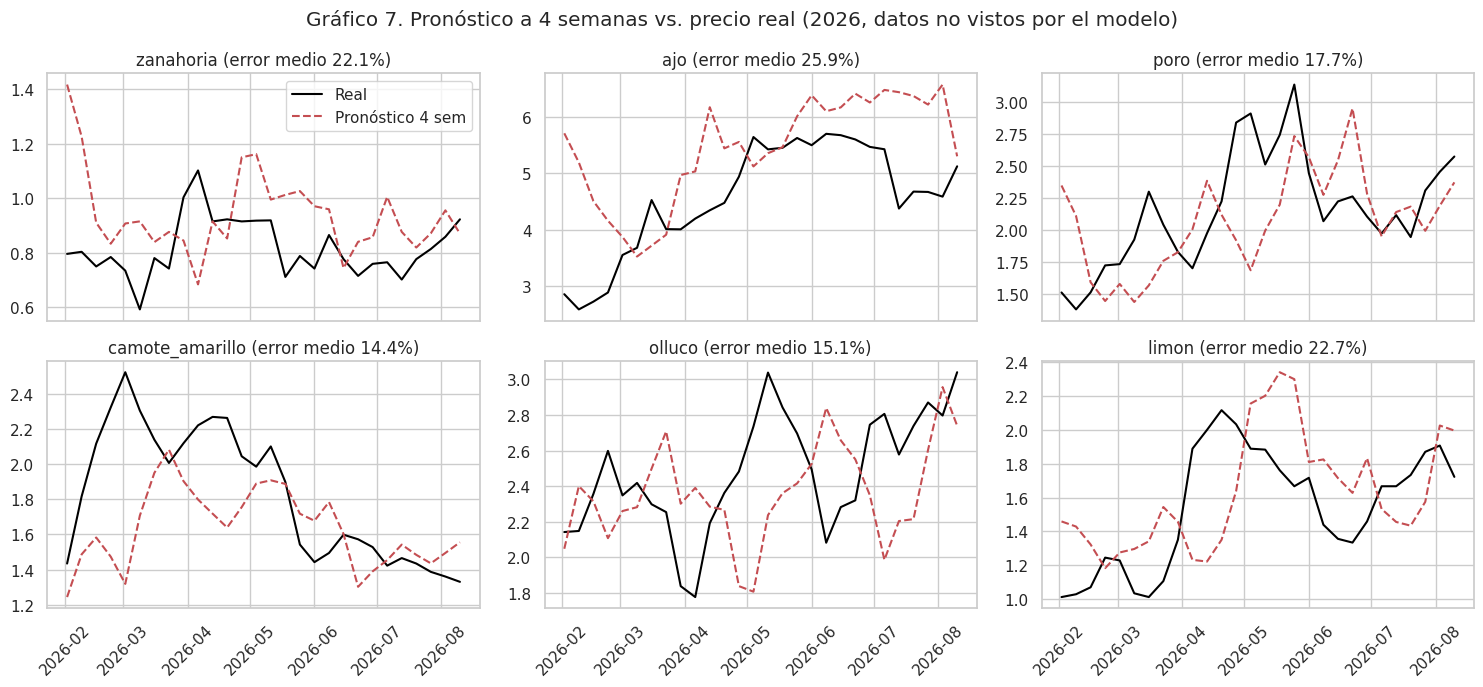

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, insumo in zip(axes.flat, SEIS):
    e = eval4[eval4["insumo_estandar"] == insumo]
    ax.plot(e["fecha"] + pd.Timedelta(weeks=4), e["precio_futuro"], label="Real", color="black")
    ax.plot(e["fecha"] + pd.Timedelta(weeks=4), e["pred_modelo"], label="Pronóstico 4 sem", color="#C44E52", linestyle="--")
    ax.set_title(f"{insumo} (error medio {error_insumo.loc[insumo, 'error_modelo_pct']:.1f}%)")
    ax.tick_params(axis="x", rotation=45)
axes.flat[0].legend()
fig.suptitle("Gráfico 7. Pronóstico a 4 semanas vs. precio real (2026, datos no vistos por el modelo)")
plt.tight_layout(); plt.show()

### 6.2 ¿Con cuánta anticipación se puede ver venir el precio?
Repetimos el modelo para horizontes de 1, 2, 4 y 8 semanas. Mientras más lejos miramos, más crece el error.
Esto responde la segunda mitad de la pregunta central del caso.

In [21]:
filas = []
for h in [1, 2, 4, 8]:
    d_h, X_h = preparar(h)
    _, _, m = evaluar(d_h, X_h, list(X_h.columns))
    t = d_h["fecha"] >= CORTE
    mape_naive = mean_absolute_percentage_error(d_h.loc[t, "precio_futuro"], d_h.loc[t, "precio"]) * 100
    filas.append({"horizonte_semanas": h, "MAPE_modelo": m["MAPE_pct"], "MAPE_ingenuo": mape_naive})
horizontes = pd.DataFrame(filas)
horizontes

,horizonte_semanas,MAPE_modelo,MAPE_ingenuo
0,1,9.70,9.82
1,2,14.89,15.06
2,4,19.13,19.82
3,8,23.67,25.70


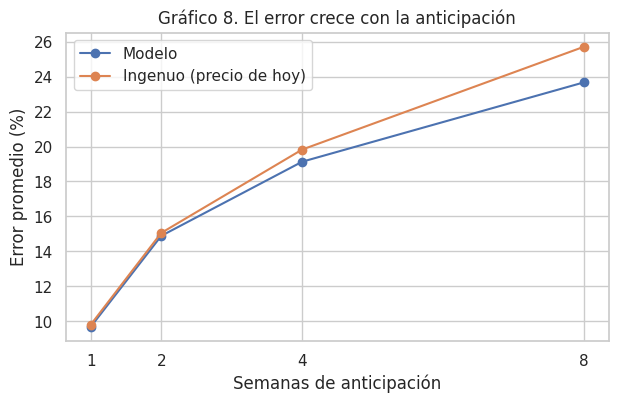

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(horizontes["horizonte_semanas"], horizontes["MAPE_modelo"], marker="o", label="Modelo")
plt.plot(horizontes["horizonte_semanas"], horizontes["MAPE_ingenuo"], marker="o", label="Ingenuo (precio de hoy)")
plt.xticks([1, 2, 4, 8]); plt.xlabel("Semanas de anticipación"); plt.ylabel("Error promedio (%)")
plt.title("Gráfico 8. El error crece con la anticipación"); plt.legend(); plt.show()

**Lectura (Gráfico 8) — con cuánta anticipación:** el error se **duplica** al pasar de 1 semana (9.7%) a 4 semanas (19.1%)
y llega a 23.7% a 8 semanas. El modelo le gana al ingenuo en todos los horizontes, más a 8 semanas (2 puntos).
**Conclusión para el cliente:** un alza se puede anticipar con confianza razonable a 1–2 semanas. Más allá de un mes, en vez de
"adivinar" el precio conviene **protegerse**: stock en los almacenables y contratos con proveedor en los perecibles volátiles.

### 6.3 Regresión logística — alerta de alza fuerte
Para el cliente, más útil que el precio exacto es saber **si viene un alza fuerte**.
Definimos alza fuerte = el precio sube **más de 10% en 4 semanas**. La regresión logística da la probabilidad
de que eso pase. Usamos `class_weight="balanced"` porque las alzas fuertes son poco frecuentes.

In [23]:
d4["alza_fuerte"] = (d4["objetivo_cambio_pct"] > 10).astype(int)
print(f"Semanas con alza fuerte: {d4['alza_fuerte'].mean()*100:.1f}% del total")

def entrenar_logit(cols):
    esc = StandardScaler().fit(X4.loc[train4, cols])
    lg = LogisticRegression(class_weight="balanced", max_iter=3000)
    lg.fit(esc.transform(X4.loc[train4, cols]), d4.loc[train4, "alza_fuerte"])
    prob = lg.predict_proba(esc.transform(X4.loc[test4, cols]))[:, 1]
    return lg, prob

y_alza = d4.loc[test4, "alza_fuerte"]
filas = []
for nombre, cols in [("Sin INEI", cols_sin), ("Con INEI", cols_con)]:
    _, prob = entrenar_logit(cols)
    pr = (prob >= 0.5).astype(int)
    filas.append({"modelo": nombre, "accuracy": accuracy_score(y_alza, pr) * 100,
                  "precision": precision_score(y_alza, pr, zero_division=0) * 100,
                  "recall": recall_score(y_alza, pr) * 100})
print(pd.DataFrame(filas).set_index("modelo").round(1).to_string(), "\n")

logit, prob_alza = entrenar_logit(cols_con)
pred_alza = (prob_alza >= 0.5).astype(int)

print(f"Exactitud (accuracy): {accuracy_score(y_alza, pred_alza)*100:.1f}%")
print(f"Precisión: de las alertas emitidas, {precision_score(y_alza, pred_alza, zero_division=0)*100:.1f}% fueron alzas reales")
print(f"Recall: de las alzas reales, el modelo detectó {recall_score(y_alza, pred_alza)*100:.1f}%")
print(f"Alzas reales en 2026: {y_alza.sum()} | alertas emitidas: {pred_alza.sum()}")
pd.DataFrame(confusion_matrix(y_alza, pred_alza),
             index=["Real: sin alza", "Real: alza"], columns=["Predicho: sin alza", "Predicho: alza"])

Semanas con alza fuerte: 34.9% del total
          accuracy  precision  recall
modelo                               
Sin INEI     63.80      47.40   72.00
Con INEI     64.30      47.10   53.30 

Exactitud (accuracy): 64.3%
Precisión: de las alertas emitidas, 47.1% fueron alzas reales
Recall: de las alzas reales, el modelo detectó 53.3%
Alzas reales en 2026: 150 | alertas emitidas: 170


,Predicho: sin alza,Predicho: alza
Real: sin alza,208,90
Real: alza,70,80


In [24]:
coef_logit = pd.Series(logit.coef_[0], index=X4.columns)[VARS_NUM]
print("Coeficientes estandarizados (signo = sube o baja la probabilidad de alza):")
print(coef_logit.round(2).to_string())

Coeficientes estandarizados (signo = sube o baja la probabilidad de alza):
cambio_1sem          -0.00
cambio_4sem          -0.28
desvio_media_12sem    0.24
log_brecha_inei       0.70


**Lectura de la alerta de alza:**
- La versión **sin INEI** detecta **72% de las alzas reales**, con 47% de precisión. La versión con INEI tiene la misma precisión (47%)
  pero detecta solo 53%.
- **Para el restaurante conviene la versión sin INEI**: una falsa alarma cuesta poco (comprar algo antes), pero no ver venir un alza cuesta margen.
  Es decir, INEI mejora el pronóstico del precio (sección 6.1), pero no la alerta.
- Lo que más sube la probabilidad de alza es un precio mayorista bajo frente al minorista (`log_brecha_inei`), seguido de un precio
  por encima de su promedio de 3 meses.

## 7. Serie de tiempo — estacionalidad y pronóstico mensual
**Método (descomposición multiplicativa clásica, hecha a mano con pandas para poder explicar cada paso):**
1. **Tendencia:** media móvil centrada de 12 meses (quita la estacionalidad). En los extremos de la serie se
   acepta con mínimo 6 meses, para no perder el primer y último semestre (los extremos de la serie).
2. **Índice estacional:** precio / tendencia, promediado por mes del año. Índice 1.20 en abril = en abril
   el insumo suele estar 20% más caro que su tendencia.
3. **Pronóstico:** último precio desestacionalizado × índice estacional del mes a pronosticar.
   Para pronosticar se usa el índice **amortiguado a la mitad** (1.20 → 1.10): el patrón de cada año
   varía bastante y usarlo completo empeora el pronóstico (lo probamos en la versión anterior y se mantiene).

**Validación:** se repite dos veces — entrenando hasta jul-2025 y hasta ene-2026 — y se pronostican los
6 meses siguientes, comparando contra el ingenuo ("el precio se queda igual que el último mes").

In [25]:
AMORTIGUACION = 0.5

def descomponer(serie_mensual):
    """serie_mensual: Serie con índice de fechas mensuales.
    Devuelve tendencia, índice estacional (12 valores) y la tabla precio/tendencia de cada mes observado."""
    tendencia = serie_mensual.rolling(12, center=True, min_periods=6).mean()
    ratio = serie_mensual / tendencia
    indice = ratio.groupby(ratio.index.month).mean()
    indice = indice.reindex(range(1, 13)).interpolate(limit_direction="both")
    indice = indice / indice.mean()
    return tendencia, indice, ratio

def pronosticar(serie_mensual, meses_adelante):
    _, indice, _ = descomponer(serie_mensual)
    indice = 1 + (indice - 1) * AMORTIGUACION
    desest = serie_mensual / serie_mensual.index.month.map(indice).values
    nivel = desest.iloc[-1]
    fechas = pd.date_range(serie_mensual.index[-1] + pd.offsets.MonthBegin(1), periods=meses_adelante, freq="MS")
    return pd.Series(nivel * fechas.month.map(indice).values, index=fechas)

# SISAP solo tiene 5 días de agosto 2026: se excluye ese mes incompleto de la serie mensual
serie_mensual = (mensual[mensual["año_mes"] < "2026-08"]
                 .pivot(index="fecha_mes", columns="insumo_estandar", values="precio_mayorista_mes"))

# Validación con dos orígenes (julio 2026 es el último mes completo)
filas = []
for insumo in serie_mensual.columns:
    s = serie_mensual[insumo]
    for corte in ["2025-08-01", "2026-02-01"]:
        entreno, prueba = s[s.index < corte], s[s.index >= corte].iloc[:6]
        pron = pronosticar(entreno, len(prueba))
        filas.append({"insumo_estandar": insumo, "corte": corte,
                      "MAPE_estacional": mean_absolute_percentage_error(prueba, pron.values) * 100,
                      "MAPE_ingenuo": mean_absolute_percentage_error(prueba, np.repeat(entreno.iloc[-1], len(prueba))) * 100})
validacion_ts = pd.DataFrame(filas).groupby("insumo_estandar")[["MAPE_estacional", "MAPE_ingenuo"]].mean()
validacion_ts["gana_estacional"] = validacion_ts["MAPE_estacional"] < validacion_ts["MAPE_ingenuo"]
validacion_ts = validacion_ts.sort_values("MAPE_estacional")
print(f"Error promedio a 1-6 meses: estacional {validacion_ts['MAPE_estacional'].mean():.1f}% vs "
      f"ingenuo {validacion_ts['MAPE_ingenuo'].mean():.1f}%. "
      f"El estacional gana en {validacion_ts['gana_estacional'].sum()} de {len(validacion_ts)} insumos.")
validacion_ts

Error promedio a 1-6 meses: estacional 24.4% vs ingenuo 26.2%. El estacional gana en 10 de 16 insumos.


,MAPE_estacional,MAPE_ingenuo,gana_estacional
insumo_estandar,,,
maiz_morado,10.94,11.89,True
papa_amarilla,14.11,18.90,True
olluco,15.55,12.30,False
ajo,15.98,27.77,True
poro,18.51,18.66,True
papa_huayro,20.05,25.98,True
zapallo_macre,21.58,19.38,False
zanahoria,23.36,20.17,False
limon,25.04,29.79,True


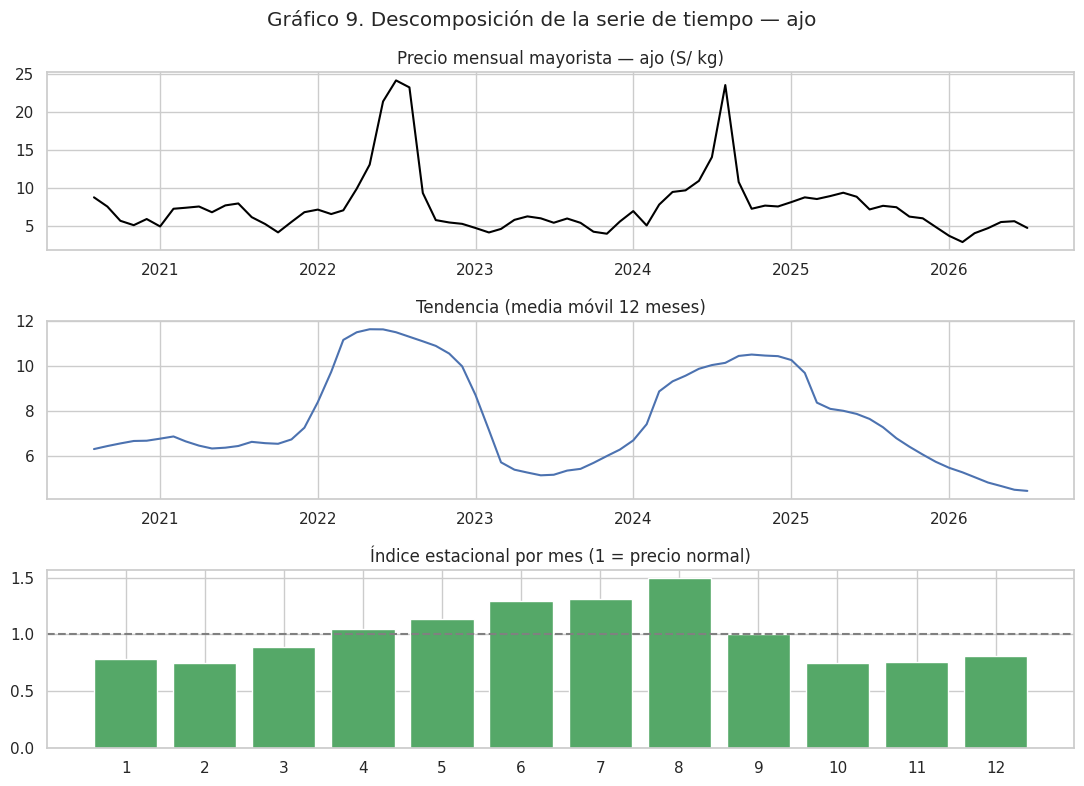

In [26]:
# Descomposición detallada del ajo (el insumo más volátil)
s_ajo = serie_mensual["ajo"]
tend_ajo, ind_ajo, _ = descomponer(s_ajo)
fig, axes = plt.subplots(3, 1, figsize=(11, 8))
axes[0].plot(s_ajo, color="black"); axes[0].set_title("Precio mensual mayorista — ajo (S/ kg)")
axes[1].plot(tend_ajo, color="#4C72B0"); axes[1].set_title("Tendencia (media móvil 12 meses)")
axes[2].bar(range(1, 13), ind_ajo.values, color="#55A868"); axes[2].axhline(1, color="gray", linestyle="--")
axes[2].set_xticks(range(1, 13)); axes[2].set_title("Índice estacional por mes (1 = precio normal)")
fig.suptitle("Gráfico 9. Descomposición de la serie de tiempo — ajo")
plt.tight_layout(); plt.show()

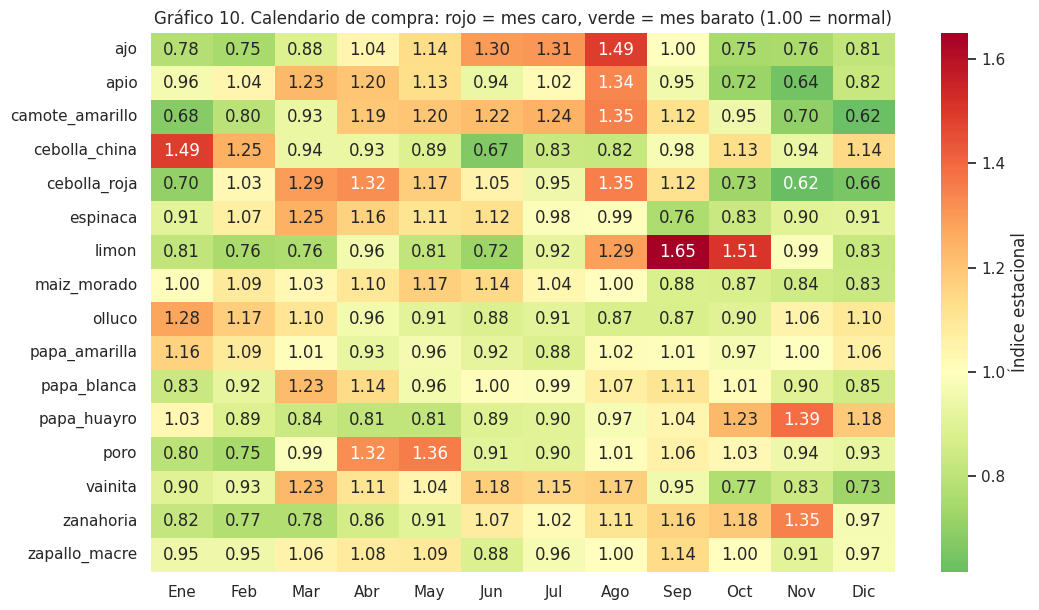

Meses caros y baratos CONSISTENTES (se repitieron en al menos 80% de los años) — insumos priorizados:
  zanahoria        caros: Ago, Sep, Oct, Nov     baratos: Ene, Feb, Mar, Abr
  ajo              caros: May, Jun, Jul, Ago     baratos: Ene, Feb, Oct, Nov, Dic
  poro             caros: Abr, May               baratos: Feb, Jul
  camote_amarillo  caros: Abr, May, Jun, Jul, Ago baratos: Ene, Feb, Nov, Dic
  olluco           caros: Ene, Feb, Mar          baratos: Ago, Sep
  limon            caros: Sep, Oct               baratos: Ene, Feb, Mar, May, Jun, Dic


In [27]:
# Índices estacionales de los 16 insumos → calendario de compra
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
indices = pd.DataFrame({ins: descomponer(serie_mensual[ins])[1] for ins in serie_mensual.columns}).T
indices.columns = MESES

# Consistencia: ¿en al menos el 80% de los años observados ese mes estuvo del mismo lado de la tendencia?
# (con 6 años, "todos los años" sería demasiado estricto: un solo año raro, como El Niño 2023, borraría el patrón)
UMBRAL_CONSISTENCIA = 0.8
consistencia = {}
for ins in serie_mensual.columns:
    ratio = descomponer(serie_mensual[ins])[2].dropna()
    por_mes = ratio.groupby(ratio.index.month)
    consistencia[ins] = (por_mes.apply(lambda r: max((r > 1).mean(), (r < 1).mean()) >= UMBRAL_CONSISTENCIA)).reindex(range(1, 13), fill_value=False)
consistencia = pd.DataFrame(consistencia).T
consistencia.columns = MESES

plt.figure(figsize=(12, 7))
sns.heatmap(indices, cmap="RdYlGn_r", center=1, annot=True, fmt=".2f", cbar_kws={"label": "Índice estacional"})
plt.title("Gráfico 10. Calendario de compra: rojo = mes caro, verde = mes barato (1.00 = normal)")
plt.show()

calendario = indices.reset_index().melt(id_vars="index", var_name="mes", value_name="indice_estacional").rename(columns={"index": "insumo_estandar"})
calendario["patron_consistente"] = [consistencia.loc[i, m] for i, m in zip(calendario["insumo_estandar"], calendario["mes"])]
calendario["recomendacion"] = np.select(
    [(calendario["indice_estacional"] >= 1.10) & calendario["patron_consistente"],
     (calendario["indice_estacional"] <= 0.90) & calendario["patron_consistente"]],
    ["Mes caro: comprar antes / subir precio de carta", "Mes barato: buen momento para stockear"],
    default="Normal o sin patrón claro")
amplitud = (indices.max(axis=1) - indices.min(axis=1)).rename("amplitud_estacional")
print("Meses caros y baratos CONSISTENTES (se repitieron en al menos 80% de los años) — insumos priorizados:")
for ins in SEIS:
    c = calendario[calendario["insumo_estandar"] == ins]
    caros = c.loc[c["recomendacion"].str.startswith("Mes caro"), "mes"].tolist()
    baratos = c.loc[c["recomendacion"].str.startswith("Mes barato"), "mes"].tolist()
    print(f"  {ins:<16} caros: {', '.join(caros) or '—':<22} baratos: {', '.join(baratos) or '—'}")

**Lectura (Gráficos 9 y 10 y validación):**
- **Este es el resultado que más mejora con la data ampliada.** Con 3 años, la estacionalidad casi no servía. Con 6 años, el pronóstico
  estacional se equivoca **24.4%** a 1–6 meses contra 26.2% del ingenuo, y **gana en 10 de 16 insumos** (antes 7). Donde más ayuda:
  **ajo** (16% vs 28%), papa amarilla, papa huayro, limón y papa blanca.
- El **calendario de compra** solo marca un mes como caro o barato si ese patrón se repitió en **al menos 80% de los años**.
- Insumos priorizados:
  - **Ajo:** caro de mayo a agosto, barato de octubre a febrero → conviene stockear a fin de año.
  - **Limón:** caro en septiembre–octubre, barato en el verano (ene–mar) y en may–jun → ese es el momento de negociar un contrato.
  - **Camote:** caro de abril a agosto, barato nov–feb.
  - **Zanahoria:** cara de agosto a noviembre, barata de enero a abril. **Olluco:** caro ene–mar. **Poro:** caro abr–may.

In [28]:
# Pronóstico ago–dic 2026 con toda la historia (para el dashboard)
pronostico_mensual = pd.concat({ins: pronosticar(serie_mensual[ins], 5) for ins in serie_mensual.columns}).reset_index()
pronostico_mensual.columns = ["insumo_estandar", "fecha_mes", "precio_pronosticado"]
pronostico_mensual["ultimo_real_jul26"] = pronostico_mensual["insumo_estandar"].map(serie_mensual.iloc[-1])
pronostico_mensual["cambio_vs_jul26_pct"] = (pronostico_mensual["precio_pronosticado"] / pronostico_mensual["ultimo_real_jul26"] - 1) * 100
pronostico_mensual[pronostico_mensual["insumo_estandar"].isin(SEIS)].pivot(
    index="insumo_estandar", columns="fecha_mes", values="cambio_vs_jul26_pct").round(1)

fecha_mes,2026-08-01,2026-09-01,2026-10-01,2026-11-01,2026-12-01
insumo_estandar,,,,,
ajo,7.80,-13.40,-24.40,-24.00,-21.70
camote_amarillo,4.60,-5.40,-13.30,-24.40,-27.70
limon,19.40,38.20,30.70,3.80,-4.80
olluco,-2.10,-2.00,-0.70,7.60,9.70
poro,5.90,8.50,6.80,2.40,1.50
zanahoria,4.30,6.90,8.10,16.10,-2.60


**Lectura del pronóstico:** cambio % esperado frente a julio 2026, usado en el dashboard como referencia de corto plazo.
Por el error de validación (~24%), se presenta como **tendencia esperada**, no como precio garantizado.

## 8. PA3 — ¿Con cuántos meses de rezago llega un alza del mayorista al consumidor?
**KPI3 (declarado en la PC1):** correlación de Pearson entre el precio mayorista mensualizado (SISAP) y el precio minorista (INEI)
desplazado 0, 1, 2 y 3 meses. Se reporta el rezago con mayor correlación por insumo (columnas `rezago_niveles`, `corr_niveles_max`).

**Chequeo de robustez:** repetimos el cálculo con **cambios %** mensuales (columnas `corr_rezago_k`, `rezago_meses`). Con niveles,
dos precios que solo suben con la inflación tendrían correlación alta sin que uno cause al otro; con cambios medimos si
**el alza de un mes** se transmite. Si ambas versiones dan el mismo rezago, la conclusión es sólida.

In [29]:
mensual_c = mensual[mensual["año_mes"] < "2026-08"].sort_values(["insumo_estandar", "fecha_mes"]).copy()
mensual_c["d_mayorista"] = mensual_c.groupby("insumo_estandar")["precio_mayorista_mes"].pct_change(fill_method=None)
mensual_c["d_minorista"] = mensual_c.groupby("insumo_estandar")["precio_minorista_inei"].pct_change(fill_method=None)

filas = []
for insumo, d in mensual_c.groupby("insumo_estandar"):
    fila = {"insumo_estandar": insumo}
    for k in range(4):
        fila[f"corr_rezago_{k}"] = d["d_mayorista"].corr(d["d_minorista"].shift(-k))
    filas.append(fila)
kpi3 = pd.DataFrame(filas)

# KPI3 tal como se declaró en la PC1: correlación entre NIVELES de precio (mayorista vs minorista desplazado k meses)
filas_niv = []
for insumo, d in mensual_c.groupby("insumo_estandar"):
    corrs = [d["precio_mayorista_mes"].corr(d["precio_minorista_inei"].shift(-k)) for k in range(4)]
    filas_niv.append({"insumo_estandar": insumo, "rezago_niveles": int(np.argmax(corrs)), "corr_niveles_max": max(corrs)})
kpi3_niveles = pd.DataFrame(filas_niv)
print("KPI3 declarado (niveles): rezago con mayor correlación →",
      kpi3_niveles["rezago_niveles"].value_counts().sort_index().to_dict(), "(rezago: n.º de insumos)")
cols_r = [f"corr_rezago_{k}" for k in range(4)]
kpi3["rezago_meses"] = kpi3[cols_r].values.argmax(axis=1)
kpi3["corr_max"] = kpi3[cols_r].max(axis=1)
kpi3["traslado"] = np.select([kpi3["corr_max"] >= 0.5, kpi3["corr_max"] >= 0.3], ["Fuerte", "Moderado"], "Débil")
kpi3 = kpi3.merge(kpi3_niveles, on="insumo_estandar").sort_values("corr_max", ascending=False).reset_index(drop=True)
kpi3

KPI3 declarado (niveles): rezago con mayor correlación → {0: 12, 1: 4} (rezago: n.º de insumos)


,insumo_estandar,corr_rezago_0,corr_rezago_1,corr_rezago_2,corr_rezago_3,rezago_meses,corr_max,traslado,rezago_niveles,corr_niveles_max
0,cebolla_roja,0.88,0.33,-0.18,-0.21,0,0.88,Fuerte,0,0.94
1,limon,0.85,0.33,-0.14,-0.31,0,0.85,Fuerte,0,0.95
2,cebolla_china,0.80,0.11,-0.45,-0.06,0,0.80,Fuerte,0,0.85
3,apio,0.80,0.22,0.00,-0.17,0,0.80,Fuerte,0,0.77
4,papa_blanca,0.75,0.47,-0.05,-0.28,0,0.75,Fuerte,0,0.78
5,poro,0.74,0.27,-0.24,-0.25,0,0.74,Fuerte,0,0.78
6,zanahoria,0.71,0.18,0.17,-0.20,0,0.71,Fuerte,0,0.70
7,vainita,0.70,0.25,0.04,-0.14,0,0.70,Fuerte,0,0.79
8,papa_amarilla,0.70,0.42,0.03,-0.04,0,0.70,Fuerte,0,0.78
9,camote_amarillo,0.68,0.42,0.31,0.15,0,0.68,Fuerte,1,0.88


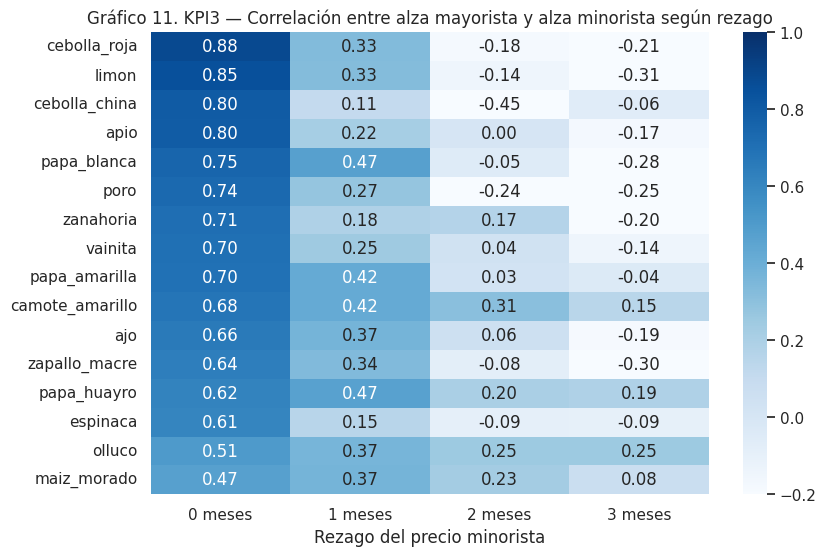

In [30]:
plt.figure(figsize=(9, 6))
sns.heatmap(kpi3.set_index("insumo_estandar")[cols_r].rename(columns=lambda c: c.replace("corr_rezago_", "") + " meses"),
            cmap="Blues", annot=True, fmt=".2f", vmin=-0.2, vmax=1)
plt.title("Gráfico 11. KPI3 — Correlación entre alza mayorista y alza minorista según rezago")
plt.xlabel("Rezago del precio minorista"); plt.ylabel("")
plt.show()

**Lectura (KPI3) — respuesta a PA3:**
- **KPI3 declarado (niveles):** en **12 de 16 insumos** el alza mayorista se refleja en el precio al consumidor **el mismo mes**; en
  camote, olluco, papa huayro y maíz morado, al mes siguiente. Las correlaciones son muy altas (0.68 a 0.95).
- **Chequeo con cambios %:** en los 16 insumos el mayor efecto es el mismo mes, y en 15 de 16 la transmisión es fuerte (≥ 0.5).
- Las dos versiones coinciden: **el traslado es de 0 a 1 mes**. Ningún insumo tarda 2 o 3 meses.
**Para el cliente:** no hay "colchón" de tiempo. Si el restaurante espera a ver el alza en el precio al público (INEI) para reaccionar,
ya llegó tarde. La señal temprana es el precio mayorista semanal de SISAP.

## 9. Clustering — segmentos de insumos por patrón de riesgo
**Unidad de análisis:** insumo (16). **Variables** (todas calculadas antes en este notebook):
- `cv_pct` — volatilidad del precio mayorista (KPI1).
- `alza_p90_4sem` — alza típica fuerte: el percentil 90 del cambio % a 4 semanas (qué tan grande es un "mal mes").
- `amplitud_estacional` — diferencia entre el mes más caro y el más barato (qué tan predecible por calendario).
- `mbc_medio` — margen de comercialización promedio (KPI2).

Se estandarizan (todas en la misma escala) y se usa K-means. El número de grupos se elige con el coeficiente de silueta.

In [31]:
alza_p90 = (semanal.assign(cambio_fut_4=semanal.groupby("insumo_estandar")["precio"].pct_change(4, fill_method=None) * 100)
            .groupby("insumo_estandar")["cambio_fut_4"].quantile(0.9).rename("alza_p90_4sem"))
features = (kpi1.set_index("insumo_estandar")[["cv_pct"]]
            .join(alza_p90).join(amplitud).join(kpi2.set_index("insumo_estandar")[["mbc_medio"]]))

X_cl = StandardScaler().fit_transform(features)
siluetas = {k: silhouette_score(X_cl, KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X_cl)) for k in range(2, 6)}
print("Silueta por número de grupos:", {k: round(v, 3) for k, v in siluetas.items()})

# Elegimos K = 3. Las siluetas de K = 2 a 5 son parecidas (0.32 a 0.37), es decir, ninguna separación es claramente mejor.
# Con K = 2 solo se separan "estables" de "no estables"; K = 3 además distingue los insumos con picos bruscos de corto plazo.
# K = 4 o 5 dejan grupos de 1–2 insumos, que no sirven para definir una política de compra.
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X_cl)
features["cluster"] = km.labels_
perfil = features.groupby("cluster").mean()
perfil["n_insumos"] = features.groupby("cluster").size()
perfil["insumos"] = features.reset_index().groupby("cluster")["insumo_estandar"].apply(", ".join)
perfil

Silueta por número de grupos: {2: np.float64(0.356), 3: np.float64(0.318), 4: np.float64(0.366), 5: np.float64(0.372)}


,cv_pct,alza_p90_4sem,amplitud_estacional,mbc_medio,n_insumos,insumos
cluster,,,,,,
0,27.08,26.72,0.37,53.34,5,"papa_blanca, papa_huayro, zapallo_macre, papa_..."
1,51.35,58.37,0.80,49.08,4,"limon, cebolla_roja, apio, cebolla_china"
2,42.62,41.05,0.58,62.74,7,"ajo, camote_amarillo, olluco, vainita, zanahor..."


In [32]:
# Nombre de negocio para cada segmento según su perfil (por reglas, para que sea reproducible):
# - el grupo con menor volatilidad = Estables
# - de los otros dos, el de mayor alza de corto plazo (p90) = Picos bruscos
# - el restante = Volátiles de alto margen
c_estable = perfil["cv_pct"].idxmin()
resto = perfil.drop(index=c_estable)
c_picos = resto["alza_p90_4sem"].idxmax()
c_volatil = resto.drop(index=c_picos).index[0]
nombres = {c_estable: "Estables: compra al día",
           c_picos: "Picos bruscos: vigilar semana a semana",
           c_volatil: "Volátiles de alto margen: comprar en mayorista"}
features["segmento"] = features["cluster"].map(nombres)
print(features.sort_values(["segmento", "cv_pct"], ascending=[True, False])[["segmento", "cv_pct", "alza_p90_4sem", "amplitud_estacional", "mbc_medio"]].round(1).to_string())

                                                       segmento  cv_pct  alza_p90_4sem  amplitud_estacional  mbc_medio
insumo_estandar                                                                                                       
papa_blanca                             Estables: compra al día   33.60          30.80                 0.40      57.70
papa_huayro                             Estables: compra al día   30.00          23.10                 0.60      54.30
zapallo_macre                           Estables: compra al día   24.70          24.80                 0.30      55.10
papa_amarilla                           Estables: compra al día   24.40          26.60                 0.30      50.30
maiz_morado                             Estables: compra al día   22.60          28.40                 0.30      49.20
limon                    Picos bruscos: vigilar semana a semana   68.00          54.70                 0.90      63.10
cebolla_roja             Picos bruscos: vigilar 

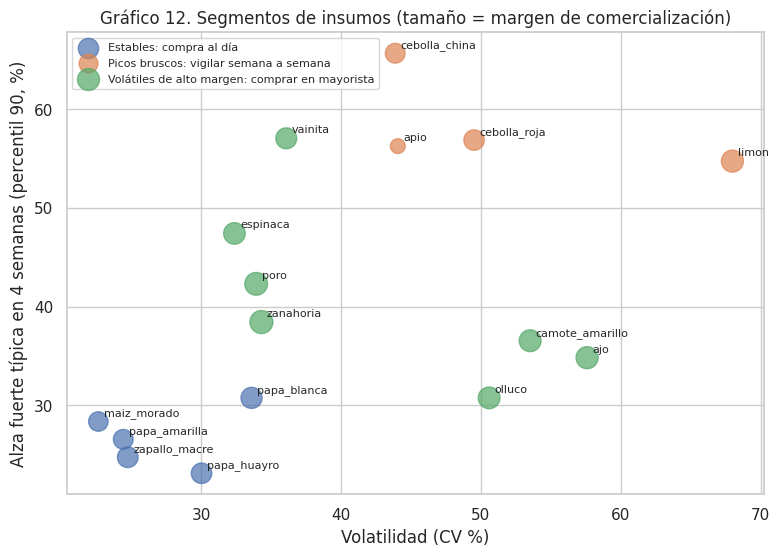

In [33]:
plt.figure(figsize=(9, 6))
for seg, d in features.groupby("segmento"):
    plt.scatter(d["cv_pct"], d["alza_p90_4sem"], s=d["mbc_medio"].clip(lower=5) * 4, alpha=0.7, label=seg)
for ins, r in features.iterrows():
    plt.annotate(ins, (r["cv_pct"], r["alza_p90_4sem"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Volatilidad (CV %)"); plt.ylabel("Alza fuerte típica en 4 semanas (percentil 90, %)")
plt.title("Gráfico 12. Segmentos de insumos (tamaño = margen de comercialización)")
plt.legend(loc="upper left", fontsize=8); plt.show()

**Lectura de los segmentos (Gráfico 12):**
| Segmento | Insumos | Perfil | Política de compra |
|---|---|---|---|
| **Picos bruscos** | limón, cebolla roja, apio, cebolla china | La mayor volatilidad (CV ~51%) y alzas de corto plazo muy fuertes (1 de cada 10 veces suben ~58% en 4 semanas) | Vigilar SISAP semana a semana; contrato de precio con proveedor (limón); compra anticipada solo en cebolla roja (calendario validado) |
| **Volátiles de alto margen** | ajo, camote, olluco, vainita, zanahoria, poro, espinaca | Volatilidad media-alta (CV ~43%) y el mayor margen de cadena (63%) | Comprar en el mayorista y colchón en la carta. **No stockear**: la simulación muestra que anticipar no ahorra en ajo ni camote |
| **Estables** | papas (blanca, huayro, amarilla), zapallo, maíz morado | Menor volatilidad (CV ~27%) | Compra al día; en papa huayro y zapallo, adelantar la compra antes de sus meses caros (calendario validado) |

**Cambio respecto de la versión de 3 años:** el limón y la cebolla roja pasan al segmento de picos bruscos. Con más historia se ve que su
riesgo no es tanto "volatilidad sostenida" sino **saltos repentinos** (como el limón en sep-2023).
*Nota:* la silueta es baja (0.32), así que los segmentos son una guía de gestión, no grupos perfectamente separados.
El segmento con **mayor oportunidad** se calcula en la sección 12.2, después de traducir todo a soles.

## 10. Pregunta huérfana y PA4 — el precio real en el punto de compra
**Pregunta huérfana:** ¿qué tan grande es la diferencia entre el precio mayorista de SISAP y el precio real que
paga un restaurante en el punto de compra, y esa brecha es distinta según el insumo?

Sin el relevamiento solo tendríamos el promedio mensual de INEI para todo Lima. El relevamiento agrega
**establecimiento y distrito**, que el Estado no publica.

In [34]:
huerfana = relev.groupby("insumo_estandar").agg(
    n_obs=("precio_soles", "count"),
    precio_relevado=("precio_soles", "mean"),
    precio_mayorista_ref=("precio_mayorista_ref", "first"),
    precio_inei_ago26=("precio_inei_ultimo_mes", "first"),
    brecha_relev_pct=("brecha_vs_mayorista_pct", "mean"),
).reset_index()
huerfana = huerfana.merge(resumen_brecha[["insumo_estandar", "brecha_media"]].rename(columns={"brecha_media": "brecha_hist_inei_pct"}),
                          on="insumo_estandar", how="left")
huerfana["brecha_inei_ago26_pct"] = (huerfana["precio_inei_ago26"] / huerfana["precio_mayorista_ref"] - 1) * 100
# KPI4: diferencia entre lo observado y lo que dice INEI
huerfana["kpi4_dif_pct"] = (huerfana["precio_relevado"] - huerfana["precio_inei_ago26"]) / huerfana["precio_relevado"] * 100
huerfana["kpi4_dif_soles"] = huerfana["precio_relevado"] - huerfana["precio_inei_ago26"]
huerfana["alerta_inei"] = (huerfana["kpi4_dif_pct"].abs() > 10) | (huerfana["kpi4_dif_soles"].abs() > 0.5)

# KPI4 por observación, como se declaró en la PC1 (cada precio de septiembre vs. INEI agosto 2026)
relev["kpi4_dif_pct"] = (relev["precio_soles"] - relev["precio_inei_ultimo_mes"]) / relev["precio_soles"] * 100
relev["kpi4_alerta"] = (relev["kpi4_dif_pct"].abs() > 10) | ((relev["precio_soles"] - relev["precio_inei_ultimo_mes"]).abs() > 0.5)
print(f"KPI4 por observación: {relev['kpi4_alerta'].sum()} de {len(relev)} precios relevados ({relev['kpi4_alerta'].mean()*100:.0f}%) "
      f"superan el umbral de alerta (>10% o >S/ 0.50 de diferencia con INEI)")
huerfana = huerfana.sort_values("brecha_relev_pct", ascending=False).reset_index(drop=True)
print(f"Brecha promedio relevamiento vs mayorista: {relev['brecha_vs_mayorista_pct'].mean():.0f}% "
      f"(mediana {relev['brecha_vs_mayorista_pct'].median():.0f}%)")
print(f"Insumos donde INEI no representa bien el precio observado (alerta KPI4): "
      f"{huerfana['alerta_inei'].sum()} de {len(huerfana)}")
huerfana

KPI4 por observación: 119 de 147 precios relevados (81%) superan el umbral de alerta (>10% o >S/ 0.50 de diferencia con INEI)
Brecha promedio relevamiento vs mayorista: 140% (mediana 135%)
Insumos donde INEI no representa bien el precio observado (alerta KPI4): 12 de 16


,insumo_estandar,n_obs,precio_relevado,precio_mayorista_ref,precio_inei_ago26,brecha_relev_pct,brecha_hist_inei_pct,brecha_inei_ago26_pct,kpi4_dif_pct,kpi4_dif_soles,alerta_inei
0,limon,9,8.04,1.77,4.74,353.92,187.97,167.61,41.04,3.30,True
1,papa_blanca,9,3.17,0.97,2.61,228.05,149.87,170.38,17.58,0.56,True
2,papa_huayro,9,4.70,1.52,4.07,209.54,128.44,168.18,13.36,0.63,True
3,zanahoria,9,2.41,0.80,3.16,201.63,245.33,296.23,-31.36,-0.75,True
4,papa_amarilla,9,5.89,1.96,4.85,199.56,108.18,146.86,17.59,1.04,True
5,camote_amarillo,9,3.88,1.41,3.35,175.64,197.28,137.99,13.66,0.53,True
6,espinaca,9,6.47,2.49,6.60,160.20,170.55,165.25,-1.94,-0.13,False
7,cebolla_china,9,7.34,3.05,6.73,140.25,120.29,120.32,8.30,0.61,True
8,maiz_morado,9,5.52,2.47,5.64,123.50,104.39,128.18,-2.09,-0.12,False
9,cebolla_roja,9,3.97,1.78,3.59,123.26,138.81,101.89,9.57,0.38,False


**Lectura — respuesta a la pregunta huérfana y a PA4:**
- En el punto de compra se paga en promedio **140% sobre el precio mayorista** (mediana 135%). Pero la brecha es **muy distinta
  según el insumo**: va de **−6% en apio** (más barato que la referencia mayorista) a **+354% en limón**.
- **El relevamiento cambia conclusiones que INEI sola habría dado mal** (ahora con 9 a 11 precios por insumo, no 1–8):
  - **Limón:** INEI dice S/ 4.74 por kg; en los mercados se pagó **S/ 8.04** (S/ 3.30 más). La brecha real casi duplica la histórica: alerta activa.
  - **Ajo:** INEI dice S/ 18.29 por kg; en los mercados se pagó **S/ 9.21**. INEI sobreestima el ajo al doble del precio real
    (puede deberse a que INEI mide "ajo entero" y SISAP "ajo criollo").
  - **Poro y olluco:** con INEI parecerían insumos de brecha muy alta (221% y 195% históricos), pero en el punto de compra salieron en 80% y 48%.
- **KPI4 (PA4):** **81% de los precios relevados** (119 de 147) se alejan de INEI más de 10% o más de S/ 0.50, y en **12 de 16 insumos** el
  promedio está en alerta. **Respuesta a PA4: el dato INEI no es confiable para fijar la carta de un restaurante**: sirve como tendencia
  de Lima, pero el precio de carta debe calcularse con el precio del proveedor real.
- Con la ampliación, los hallazgos de la versión de 60 precios **se confirman**: los valores por insumo casi no cambiaron.
- **Limitación:** 147 observaciones en 10 días de septiembre; no captura variación entre meses.

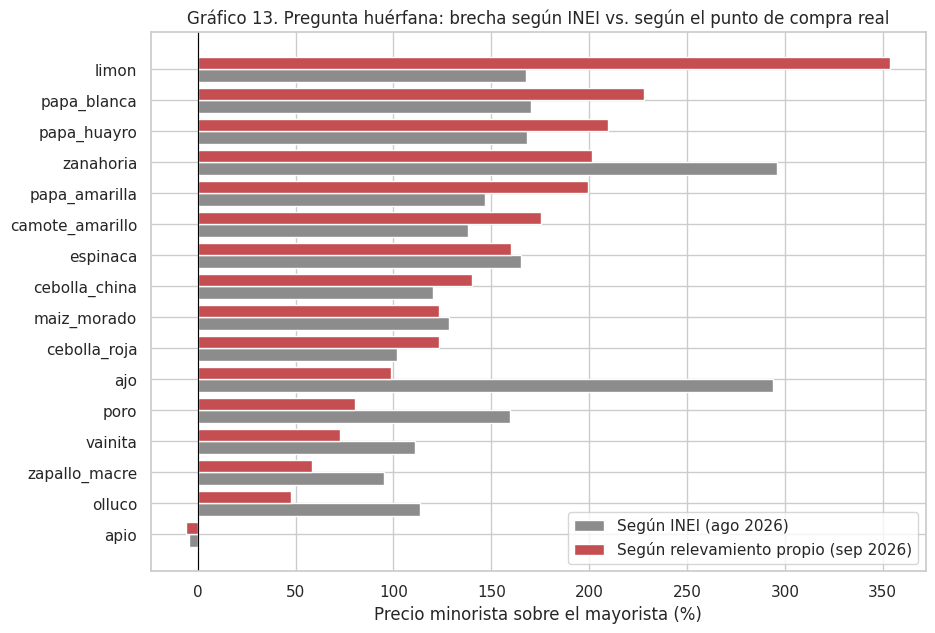

In [35]:
h = huerfana.sort_values("brecha_relev_pct")
y = np.arange(len(h))
plt.figure(figsize=(10, 7))
plt.barh(y - 0.2, h["brecha_inei_ago26_pct"], height=0.4, label="Según INEI (ago 2026)", color="#8C8C8C")
plt.barh(y + 0.2, h["brecha_relev_pct"], height=0.4, label="Según relevamiento propio (sep 2026)", color="#C44E52")
plt.yticks(y, h["insumo_estandar"]); plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Precio minorista sobre el mayorista (%)")
plt.title("Gráfico 13. Pregunta huérfana: brecha según INEI vs. según el punto de compra real")
plt.legend(); plt.show()

In [36]:
por_distrito = relev.groupby("distrito").agg(
    n_obs=("precio_soles", "count"),
    sobreprecio_medio_pct=("brecha_vs_mayorista_pct", "mean"),
    sobreprecio_mediano_pct=("brecha_vs_mayorista_pct", "median"),
    dispersion_pct=("brecha_vs_mayorista_pct", "std"),
).sort_values("sobreprecio_mediano_pct")
por_distrito

,n_obs,sobreprecio_medio_pct,sobreprecio_mediano_pct,dispersion_pct
distrito,,,,
Surquillo,49,130.10,127.37,84.31
Barranco,48,139.37,137.60,93.37
Miraflores,50,150.94,148.69,94.23


**Lectura por distrito:** la mediana del sobreprecio sobre el mayorista es **127% en Surquillo**, 138% en Barranco y **149% en Miraflores**.
Surquillo sigue siendo el más barato, pero la diferencia entre distritos (22 puntos) es pequeña frente a la diferencia entre comprar
en el mayorista o en cualquier mercado minorista (~135 puntos). Con 60 precios, Barranco parecía el más caro; con 147 ya no:
**era ruido de una muestra chica**.

## 11. ¿Cuánta plata habría ahorrado el restaurante? (simulación sobre 2026)
Hasta aquí medimos errores en %. Al cliente le importa **en soles**. Simulamos qué habría pasado en 2026
(datos que los modelos nunca vieron) con cuatro formas de comprar cada insumo:

| Estrategia | Regla |
|---|---|
| **Al día** (lo que hace hoy) | Compra cada semana lo que usa esa semana |
| **Alerta sin INEI** | Si la alerta de alza (regresión logística sin INEI) se enciende, compra por adelantado las semanas que el insumo aguanta guardado |
| **Alerta con INEI** | Igual, con la alerta que usa la brecha INEI |
| **Información perfecta** | Igual, pero la alerta se enciende solo cuando de verdad viene un alza (sabiendo el futuro). No es posible en la realidad: es el **techo** de esta regla |

**Supuestos (editables):**
- Consumo constante de 1 kg por semana por insumo. El ahorro sale en %, y luego se escala al volumen de la cadena (sección 12).
- Guardar stock cuesta **1% del valor por semana** (merma + espacio + plata inmovilizada).
- Semanas que cada insumo aguanta almacenado en condiciones adecuadas: supuesto del equipo según si es tubérculo/bulbo
  (aguanta más) o hortaliza de hoja/fruta fresca (aguanta menos). Debe validarse con el jefe de cocina.

In [37]:
COSTO_ALMACEN_SEMANAL = 0.01
VIDA_UTIL_SEM = {
    "ajo": 4, "cebolla_roja": 4, "camote_amarillo": 4, "papa_amarilla": 4, "papa_blanca": 4, "papa_huayro": 4,
    "zapallo_macre": 4, "maiz_morado": 4, "zanahoria": 3, "olluco": 2, "limon": 2, "poro": 2,
    "apio": 1, "vainita": 1, "espinaca": 1, "cebolla_china": 1,
}

def simular(precios, alertas, vida):
    """Costo total de comprar 1 kg/semana. Si hay alerta, compra 'vida' semanas por adelantado al precio de hoy."""
    costo, stock = 0.0, 0
    for t, p in enumerate(precios):
        if stock > 0:
            stock -= 1                                  # se consume lo que ya se compró
        elif alertas[t] and vida > 1:
            k = min(vida, len(precios) - t)             # semanas que se compran hoy
            costo += p * k + p * COSTO_ALMACEN_SEMANAL * sum(range(k))
            stock = k - 1
        else:
            costo += p                                  # compra al día
    return costo

_, prob_sin = entrenar_logit(cols_sin)
_, prob_con = entrenar_logit(cols_con)
bt = d4.loc[test4, ["insumo_estandar", "fecha", "precio", "alza_fuerte"]].copy()
bt["alerta_sin_inei"] = prob_sin >= 0.5
bt["alerta_con_inei"] = prob_con >= 0.5

filas = []
for insumo, d in bt.sort_values("fecha").groupby("insumo_estandar"):
    precios, vida = d["precio"].values, VIDA_UTIL_SEM[insumo]
    al_dia = precios.sum()
    fila = {"insumo_estandar": insumo, "vida_util_sem": vida, "gasto_al_dia": al_dia}
    for nombre, col in [("alerta_sin_inei", "alerta_sin_inei"), ("alerta_con_inei", "alerta_con_inei"), ("info_perfecta", "alza_fuerte")]:
        fila[f"ahorro_{nombre}_pct"] = (1 - simular(precios, d[col].values.astype(bool), vida) / al_dia) * 100
    filas.append(fila)
ahorro_alerta = pd.DataFrame(filas).sort_values("ahorro_info_perfecta_pct", ascending=False).reset_index(drop=True)

total = {e: (1 - sum(r["gasto_al_dia"] * (1 - r[f"ahorro_{e}_pct"] / 100) for _, r in ahorro_alerta.iterrows())
             / ahorro_alerta["gasto_al_dia"].sum()) * 100 for e in ["alerta_sin_inei", "alerta_con_inei", "info_perfecta"]}
print("Ahorro total sobre el gasto en los 16 insumos (2026):")
for e, v in total.items():
    print(f"   {e:<17} {v:5.1f}%")
ahorro_alerta.round(1)

Ahorro total sobre el gasto en los 16 insumos (2026):
   alerta_sin_inei     0.3%
   alerta_con_inei    -0.3%
   info_perfecta       1.1%


,insumo_estandar,vida_util_sem,gasto_al_dia,ahorro_alerta_sin_inei_pct,ahorro_alerta_con_inei_pct,ahorro_info_perfecta_pct
0,camote_amarillo,4,51.60,5.80,0.00,6.10
1,maiz_morado,4,90.00,0.10,-2.00,3.50
2,papa_blanca,4,36.50,2.60,1.40,2.70
3,ajo,4,124.90,-0.20,-1.70,2.40
4,zanahoria,3,24.00,-3.60,-2.40,1.70
5,papa_huayro,4,51.50,0.60,0.30,1.40
6,papa_amarilla,4,72.60,-1.60,-0.40,0.80
7,poro,2,60.10,-0.10,-0.00,0.50
8,limon,2,40.60,0.70,0.50,0.40
9,olluco,2,66.20,0.90,0.50,0.40


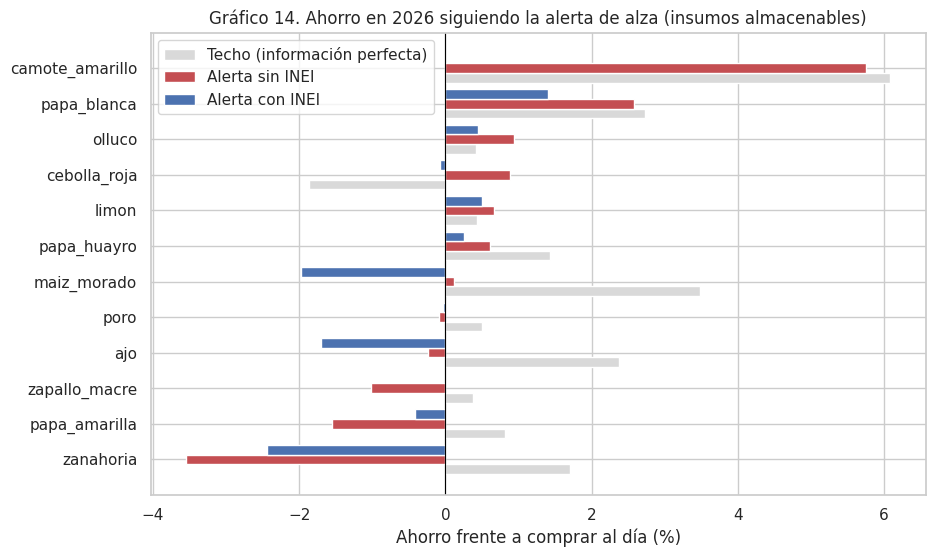

In [38]:
fig, ax = plt.subplots(figsize=(10, 6))
a = ahorro_alerta[ahorro_alerta["vida_util_sem"] > 1].sort_values("ahorro_alerta_sin_inei_pct")
y = np.arange(len(a))
ax.barh(y - 0.27, a["ahorro_info_perfecta_pct"], height=0.27, color="#D9D9D9", label="Techo (información perfecta)")
ax.barh(y, a["ahorro_alerta_sin_inei_pct"], height=0.27, color="#C44E52", label="Alerta sin INEI")
ax.barh(y + 0.27, a["ahorro_alerta_con_inei_pct"], height=0.27, color="#4C72B0", label="Alerta con INEI")
ax.set_yticks(y); ax.set_yticklabels(a["insumo_estandar"]); ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Ahorro frente a comprar al día (%)")
ax.set_title("Gráfico 14. Ahorro en 2026 siguiendo la alerta de alza (insumos almacenables)")
ax.legend(); plt.show()

**Lectura (Gráfico 14):** este es el hallazgo más importante de la simulación. **Ni siquiera sabiendo el futuro** se ahorra más de
~1% del gasto anticipando compras: en los mejores insumos (camote, maíz morado, papa blanca) el techo es de 3–6%.
Las alertas reales quedan entre −0.3% y +0.3% en total (la alerta sin INEI ahorra 5.8% en camote, pero pierde en otros).
El motivo: las alzas fuertes duran poco y guardar stock tiene un costo.
**Conclusión honesta:** comprar "en el momento justo" casi no mueve la aguja. Hay que buscar el ahorro en otro lado (ver sección 12).

### 11.2 Estrategia por calendario
Regla: si **el mes que viene** es un mes caro consistente (según la estacionalidad aprendida **solo con datos hasta jul-2025**),
el restaurante compra este mes lo del mes siguiente. Solo aplica a insumos que aguantan 4 semanas guardados.
Se evalúa de ago-2025 a jul-2026, un año que el calendario no vio.

In [39]:
filas = []
for insumo in serie_mensual.columns:
    s = serie_mensual[insumo]
    entreno, prueba = s[s.index < "2025-08-01"], s[s.index >= "2025-08-01"]
    _, indice, ratio = descomponer(entreno)
    r = ratio.dropna()
    consistente = r.groupby(r.index.month).apply(lambda x: (x > 1).mean() >= UMBRAL_CONSISTENCIA)
    caro = {m: (indice[m] >= 1.10) and bool(consistente.get(m, False)) for m in range(1, 13)}
    al_dia, calendario_costo, meses_adelantados = prueba.sum(), 0.0, 0
    for i, (fecha, precio) in enumerate(prueba.items()):
        comprado_antes = i > 0 and caro[fecha.month] and VIDA_UTIL_SEM[insumo] >= 4
        if comprado_antes:
            calendario_costo += prueba.iloc[i - 1] * (1 + COSTO_ALMACEN_SEMANAL * 4)
            meses_adelantados += 1
        else:
            calendario_costo += precio
    filas.append({"insumo_estandar": insumo, "meses_comprados_antes": meses_adelantados,
                  "ahorro_calendario_pct": (1 - calendario_costo / al_dia) * 100})
ahorro_calendario = pd.DataFrame(filas).sort_values("ahorro_calendario_pct", ascending=False).reset_index(drop=True)
ahorro_calendario[ahorro_calendario["meses_comprados_antes"] > 0].round(1)

,insumo_estandar,meses_comprados_antes,ahorro_calendario_pct
0,cebolla_roja,2,3.90
1,papa_huayro,3,3.40
2,zapallo_macre,2,1.40
3,papa_amarilla,1,0.60
13,ajo,3,-1.00
14,maiz_morado,2,-2.80
15,camote_amarillo,4,-5.80


**Lectura del calendario:** comprar por adelantado antes de un mes caro funciona en **cebolla roja (+3.9%)**, **papa huayro (+3.4%)**,
zapallo y papa amarilla, pero **empeora** en camote, maíz morado y ajo. El calendario sirve como guía para pocos insumos, no como regla general.

## 12. Costo por plato: cuánto mueve la volatilidad el costo de la carta
Traducimos los precios a **platos criollos** que usan los insumos priorizados. Solo se cuenta el costo de los insumos
de este estudio (no pescado, carne, aceite ni ajíes), así que es el **costo de verduras y tubérculos del plato**.

**Recetas estándar (fuentes):**
- **Cebiche** — receta de PromPerú publicada por ¡Hola!: 1 kg de pescado, 20 limones, 2 camotes grandes, 1 cebolla roja grande,
  1½ cdta de ajo molido. La fuente no indica porciones: asumimos **4** (250 g de pescado por porción).
- **Ají de gallina** — La República (Buenazo), **4 porciones**: ½ kg de papa amarilla, 2 cebollas, 1 zanahoria, 1 tallo de apio,
  2 dientes de ajo + 2 cdas de ajo molido (salsa y arroz).
- **Sancochado** — Comida-peruana.com, **8 porciones**: 4 zanahorias, 2 poros, 4 tallos de apio, 8 papas blancas.
- **Olluquito con charqui** — Comida-peruana.com, **6 porciones**: 1 kg de olluco, 1 cebolla, 1 cda de ajo molido.

**Pesos por unidad:** INS/CENAN-MINSA, *Tablas auxiliares para la formulación y evaluación de regímenes alimentarios* (2.ª ed., 2016):
diente de ajo mediano 5.9 g, cebolla roja mediana 199.3 g y grande 297.6 g, zanahoria mediana 180.3 g, rama de apio 15 g.
**Supuestos del equipo** (la tabla no los da de forma legible): limón sutil 30 g, camote grande 300 g, poro 250 g,
papa blanca 150 g, 1 cda de ajo molido 15 g y 1 cdta 5 g. Cuando la receta dice "cebolla", se asume cebolla roja.
Todo es editable: lo ideal es reemplazarlo por la ficha técnica real del restaurante.

In [40]:
G = {"ajo_diente": 5.9, "cebolla_roja_mediana": 199.3, "cebolla_roja_grande": 297.6, "zanahoria_mediana": 180.3,
     "apio_rama": 15.0, "limon_unidad": 30.0, "camote_grande": 300.0, "poro_unidad": 250.0,
     "papa_blanca_unidad": 150.0, "ajo_cda": 15.0, "ajo_cdta": 5.0}

# gramos de cada insumo por PORCIÓN = cantidad de la receta / porciones
RECETAS = {
    "Cebiche": {"porciones": 4, "limon": 20 * G["limon_unidad"], "camote_amarillo": 2 * G["camote_grande"],
                "cebolla_roja": G["cebolla_roja_grande"], "ajo": 1.5 * G["ajo_cdta"]},
    "Ají de gallina": {"porciones": 4, "papa_amarilla": 500, "cebolla_roja": 2 * G["cebolla_roja_mediana"],
                       "zanahoria": G["zanahoria_mediana"], "apio": G["apio_rama"], "ajo": 2 * G["ajo_diente"] + 2 * G["ajo_cda"]},
    "Sancochado": {"porciones": 8, "zanahoria": 4 * G["zanahoria_mediana"], "poro": 2 * G["poro_unidad"],
                   "apio": 4 * G["apio_rama"], "papa_blanca": 8 * G["papa_blanca_unidad"]},
    "Olluquito con charqui": {"porciones": 6, "olluco": 1000, "cebolla_roja": G["cebolla_roja_mediana"], "ajo": G["ajo_cda"]},
}
gramos = pd.DataFrame([{"plato": pl, "insumo_estandar": ins, "gramos_por_porcion": g / r["porciones"]}
                       for pl, r in RECETAS.items() for ins, g in r.items() if ins != "porciones"])
print(gramos.pivot(index="insumo_estandar", columns="plato", values="gramos_por_porcion").round(1).fillna("").to_string())

# Costo mensual por plato con el precio MAYORISTA
costo_plato = (gramos.merge(mensual[["insumo_estandar", "fecha_mes", "precio_mayorista_mes"]], on="insumo_estandar")
               .assign(costo=lambda x: x["gramos_por_porcion"] / 1000 * x["precio_mayorista_mes"])
               .groupby(["plato", "fecha_mes"])["costo"].sum().reset_index())

resumen_plato = costo_plato.groupby("plato")["costo"].agg(
    costo_mediano="median", costo_p90=lambda c: c.quantile(0.9), costo_min="min", costo_max="max")
resumen_plato["mes_mas_caro"] = costo_plato.loc[costo_plato.groupby("plato")["costo"].idxmax()].set_index("plato")["fecha_mes"].dt.strftime("%Y-%m")
resumen_plato["colchon_sugerido"] = resumen_plato["costo_p90"] - resumen_plato["costo_mediano"]
resumen_plato["veces_max_vs_mediana"] = resumen_plato["costo_max"] / resumen_plato["costo_mediano"]

# Mismo plato si los insumos se compran en mercados minoristas (relevamiento, sep 2026) vs. mayorista (jul-ago 2026)
precio_canal = huerfana.set_index("insumo_estandar")[["precio_relevado", "precio_mayorista_ref"]]
canal = gramos.join(precio_canal, on="insumo_estandar")
canal["c_mayorista"] = canal["gramos_por_porcion"] / 1000 * canal["precio_mayorista_ref"]
canal["c_minorista"] = canal["gramos_por_porcion"] / 1000 * canal["precio_relevado"]
canal = canal.groupby("plato")[["c_mayorista", "c_minorista"]].sum()
resumen_plato = resumen_plato.join(canal.rename(columns={"c_mayorista": "costo_hoy_mayorista", "c_minorista": "costo_hoy_mercado_minorista"}))
resumen_plato["sobrecosto_minorista_pct"] = (resumen_plato["costo_hoy_mercado_minorista"] / resumen_plato["costo_hoy_mayorista"] - 1) * 100
resumen_plato.round(2)

plato           Ají de gallina Cebiche Olluquito con charqui Sancochado
insumo_estandar                                                        
ajo                      10.40    1.90                  2.50           
apio                      3.80                                     7.50
camote_amarillo                 150.00                                 
cebolla_roja             99.60   74.40                 33.20           
limon                           150.00                                 
olluco                                                166.70           
papa_amarilla           125.00                                         
papa_blanca                                                      150.00
poro                                                              62.50
zanahoria                45.10                                    90.20


,costo_mediano,costo_p90,costo_min,costo_max,mes_mas_caro,colchon_sugerido,veces_max_vs_mediana,costo_hoy_mayorista,costo_hoy_mercado_minorista,sobrecosto_minorista_pct
plato,,,,,,,,,,
Ají de gallina,0.59,0.74,0.45,0.97,2023-08,0.15,1.63,0.53,1.35,157.14
Cebiche,0.57,0.74,0.33,1.90,2023-09,0.17,3.34,0.62,2.10,240.00
Olluquito con charqui,0.43,0.78,0.21,0.99,2023-09,0.35,2.30,0.53,0.84,57.12
Sancochado,0.36,0.44,0.23,0.52,2026-04,0.07,1.43,0.39,0.98,148.30


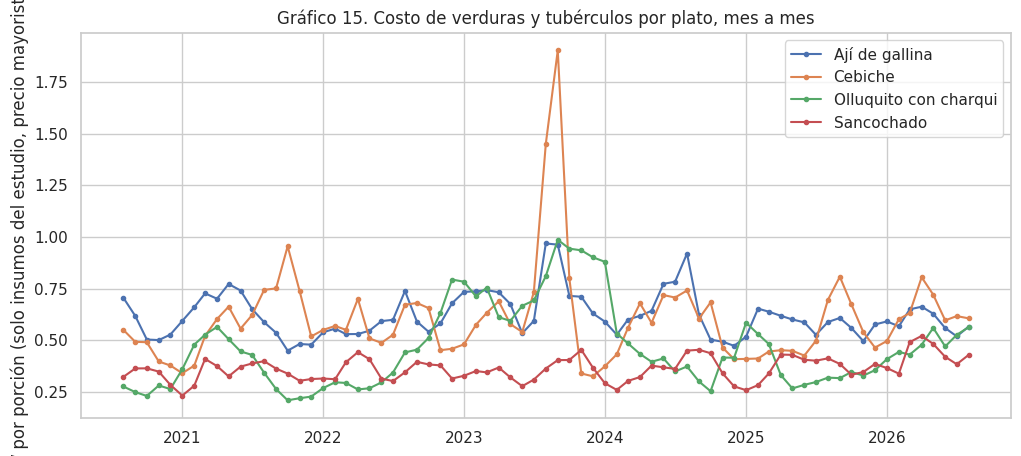

In [41]:
plt.figure(figsize=(12, 5))
for plato, d in costo_plato.groupby("plato"):
    plt.plot(d["fecha_mes"], d["costo"], marker="o", markersize=3, label=plato)
plt.ylabel("S/ por porción (solo insumos del estudio, precio mayorista)")
plt.title("Gráfico 15. Costo de verduras y tubérculos por plato, mes a mes")
plt.legend(); plt.show()

**Lectura (Gráfico 15 y tabla):**
- El **cebiche** es el plato más expuesto: su costo de verduras llegó a **3.3 veces** lo normal en sep-2023 (el pico del limón).
  Para no perder margen en un mes malo, la carta necesita un **colchón de ~S/ 0.17 por porción** (diferencia entre un mes típico y uno caro, p90).
- El **olluquito** tiene el colchón más alto (S/ 0.35) porque el olluco es casi todo su costo de verduras.
- El **sancochado** es el más estable: solo S/ 0.07 de colchón.
- **Canal de compra:** con los precios del relevamiento, las verduras del cebiche cuestan **240% más** compradas en un mercado minorista
  que en el mayorista; las del ají de gallina, 157% más.

In [42]:
# ¿Qué insumo explica el costo del plato? (participación promedio)
part = (gramos.merge(mensual.groupby("insumo_estandar")["precio_mayorista_mes"].mean().rename("precio_medio"), on="insumo_estandar")
        .assign(costo=lambda x: x["gramos_por_porcion"] / 1000 * x["precio_medio"]))
part["participacion_pct"] = part["costo"] / part.groupby("plato")["costo"].transform("sum") * 100
part.pivot(index="plato", columns="insumo_estandar", values="participacion_pct").round(0).fillna(0)

insumo_estandar,ajo,apio,camote_amarillo,cebolla_roja,limon,olluco,papa_amarilla,papa_blanca,poro,zanahoria
plato,,,,,,,,,,
Ají de gallina,13.00,2.00,0.00,27.00,0.00,0.00,52.00,0.00,0.00,6.00
Cebiche,2.00,0.00,25.00,21.00,51.00,0.00,0.00,0.00,0.00,0.00
Olluquito con charqui,4.00,0.00,0.00,12.00,0.00,84.00,0.00,0.00,0.00,0.00
Sancochado,0.00,5.00,0.00,0.00,0.00,0.00,0.00,43.00,29.00,22.00


**Lectura de la participación:** el **limón es la mitad del costo de verduras del cebiche (51%)** y el olluco el 84% del olluquito.
Por eso el riesgo de esos platos se gestiona con un solo insumo: un contrato de precio con un proveedor de limón protege al cebiche.

### 12.2 Escenario de la cadena: ¿cuánto suman los ahorros en un año?
Escenario ilustrativo (editable): cada uno de los **8 locales** vende **30 porciones diarias de cada plato**.
Con las recetas obtenemos los kg que la cadena usa al año de cada insumo y les aplicamos:
- el ahorro de la mejor estrategia **realista** (alerta sin INEI, alerta con INEI o calendario) que haya salido positiva en cada insumo, y
- el ahorro de comprar en el mayorista en vez de en un mercado minorista.

In [43]:
LOCALES, PORCIONES_DIA, DIAS = 8, 30, 360
kg_anio = (gramos.groupby("insumo_estandar")["gramos_por_porcion"].sum() / 1000 * LOCALES * PORCIONES_DIA * DIAS).rename("kg_anio")
precio_2026 = bt.groupby("insumo_estandar")["precio"].mean().rename("precio_mayorista_2026")

esc = (kg_anio.to_frame().join(precio_2026)
       .join(ahorro_alerta.set_index("insumo_estandar")[["ahorro_alerta_sin_inei_pct", "ahorro_alerta_con_inei_pct"]])
       .join(ahorro_calendario.set_index("insumo_estandar")[["ahorro_calendario_pct"]])
       .join(precio_canal))
esc["gasto_anual_mayorista"] = esc["kg_anio"] * esc["precio_mayorista_2026"]
opciones = esc[["ahorro_alerta_sin_inei_pct", "ahorro_alerta_con_inei_pct", "ahorro_calendario_pct"]]
esc["mejor_estrategia"] = opciones.idxmax(axis=1).str.replace("ahorro_", "").str.replace("_pct", "")
esc["ahorro_estrategia_pct"] = opciones.max(axis=1).clip(lower=0)
esc.loc[esc["ahorro_estrategia_pct"] == 0, "mejor_estrategia"] = "al día"
esc["ahorro_estrategia_soles"] = esc["gasto_anual_mayorista"] * esc["ahorro_estrategia_pct"] / 100
esc["ahorro_canal_soles"] = esc["kg_anio"] * (esc["precio_relevado"] - esc["precio_mayorista_ref"])
esc = esc.sort_values("ahorro_canal_soles", ascending=False)

print(f"Escenario: {LOCALES} locales × {PORCIONES_DIA} porciones/día de cada uno de los {len(RECETAS)} platos")
print(f"Gasto anual en estos insumos a precio mayorista: S/ {esc['gasto_anual_mayorista'].sum():,.0f}")
print(f"Ahorro por comprar en el momento correcto (estrategias):  S/ {esc['ahorro_estrategia_soles'].sum():,.0f} al año "
      f"({esc['ahorro_estrategia_soles'].sum() / esc['gasto_anual_mayorista'].sum() * 100:.1f}%)")
print(f"Sobrecosto evitado por comprar en mayorista y no en mercado minorista: S/ {esc['ahorro_canal_soles'].sum():,.0f} al año")
esc[["kg_anio", "gasto_anual_mayorista", "mejor_estrategia", "ahorro_estrategia_pct", "ahorro_estrategia_soles", "ahorro_canal_soles"]].round(1)

Escenario: 8 locales × 30 porciones/día de cada uno de los 4 platos
Gasto anual en estos insumos a precio mayorista: S/ 185,618
Ahorro por comprar en el momento correcto (estrategias):  S/ 3,706 al año (2.0%)
Sobrecosto evitado por comprar en mayorista y no en mercado minorista: S/ 276,345 al año


,kg_anio,gasto_anual_mayorista,mejor_estrategia,ahorro_estrategia_pct,ahorro_estrategia_soles,ahorro_canal_soles
insumo_estandar,,,,,,
limon,"12,960.00","18,796.90",alerta_sin_inei,0.70,124.50,"81,243.10"
papa_amarilla,"10,800.00","27,989.00",calendario,0.60,172.50,"42,345.20"
cebolla_roja,"17,907.80","32,870.10",calendario,3.90,"1,280.00","39,249.80"
camote_amarillo,"12,960.00","23,866.80",alerta_sin_inei,5.80,"1,374.50","32,041.70"
papa_blanca,"12,960.00","16,912.30",alerta_sin_inei,2.60,435.90,"28,529.80"
olluco,"14,400.00","34,036.50",alerta_sin_inei,0.90,318.10,"18,987.70"
zanahoria,"11,683.40","10,016.70",al día,0.00,0.00,"18,787.50"
poro,"5,400.00","11,584.10",al día,0.00,0.00,"9,613.50"
ajo,"1,280.90","5,713.90",al día,0.00,0.00,"5,856.40"


In [44]:
# ¿Qué segmento del clustering representa la mayor oportunidad?
oportunidad = (features.groupby("segmento").agg(n_insumos=("cv_pct", "size"), cv_medio=("cv_pct", "mean"), mbc_medio=("mbc_medio", "mean"))
               .join(esc.join(features["segmento"]).groupby("segmento")[["ahorro_canal_soles", "ahorro_estrategia_soles"]].sum())
               .sort_values("ahorro_canal_soles", ascending=False))
oportunidad

,n_insumos,cv_medio,mbc_medio,ahorro_canal_soles,ahorro_estrategia_soles
segmento,,,,,
Picos bruscos: vigilar semana a semana,4,51.35,49.08,"120,183.74","1,404.50"
Volátiles de alto margen: comprar en mayorista,7,42.62,62.74,"85,286.77","1,692.64"
Estables: compra al día,5,27.08,53.34,"70,874.96",608.38


**Lectura — ¿qué segmento representa la mayor oportunidad?**
**Picos bruscos (limón, cebolla roja, apio, cebolla china).** En el escenario de la cadena concentra **~S/ 120,000 al año** del ahorro por
comprar en el mayorista (el limón solo aporta S/ 81,000) y es además el segmento más riesgoso (CV 51%).
Es donde una sola decisión (centralizar la compra y negociar un contrato de limón) protege más margen. Le siguen los volátiles
de alto margen (~S/ 85,000) y los estables (~S/ 71,000).

**Lectura — el insight central del proyecto:**
- Elegir **cuándo** comprar ahorra unos **S/ 3,700 al año** (2.0% del gasto). Y es una cifra optimista, porque elige
  a posteriori la mejor estrategia de cada insumo.
- Elegir **dónde** comprar (mayorista en vez de mercado minorista) evita unos **S/ 276,000 al año** de sobrecosto, **unas 75 veces más**.
  El limón solo representa S/ 81,000 de esa diferencia.
- **Ojo:** comprar en el Gran Mercado Mayorista tiene costos que aquí no están (transporte, una persona que vaya de madrugada, compra
  en volumen). Aun si esos costos fueran altos, la diferencia es tan grande que justifica evaluar un comprador centralizado para los 8 locales.
- **Recomendación:** la prioridad no es "adivinar el precio", sino **centralizar la compra en el mayorista** para los insumos de mayor
  margen de comercialización (limón, papas, cebolla roja, camote) y usar las alertas y el calendario como ajuste fino.
- Con la data ampliada esta conclusión **se mantiene igual**: es el hallazgo más robusto del proyecto.

### 12.3 El costo de comprar en el mayorista: más barato, pero más volátil
Si la recomendación es comprar en el mayorista, hay que medir su lado negativo. Dos medidas, con los mismos datos mensuales:
- **Traslado (pass-through):** cuando el precio mayorista sube o baja más de 10% en un mes, ¿qué parte de ese cambio se ve en el
  precio minorista ese mismo mes? Se calcula por separado para subidas y bajadas, para ver si el minorista "sube rápido y baja lento".
- **Volatilidad comparada:** CV del precio mayorista mensual vs. CV del precio minorista mensual (INEI).
- **Prueba de fuego:** ¿en qué % de los meses el costo de verduras de cada plato comprado en el mayorista fue **más caro** que comprarlo
  al precio minorista de ese mismo mes?

In [45]:
mc = mensual[mensual["año_mes"] < "2026-08"].sort_values(["insumo_estandar", "fecha_mes"]).copy()
gm = mc.groupby("insumo_estandar")
mc["d_may"] = gm["precio_mayorista_mes"].pct_change(fill_method=None) * 100
mc["d_min"] = gm["precio_minorista_inei"].pct_change(fill_method=None) * 100
sube, baja = mc[mc["d_may"] > 10], mc[mc["d_may"] < -10]
traslado_sube = sube["d_min"].mean() / sube["d_may"].mean()
traslado_baja = baja["d_min"].mean() / baja["d_may"].mean()
print(f"Meses con alza mayorista > 10%: {len(sube)} | el mayorista subió {sube['d_may'].mean():.0f}% en promedio, "
      f"el minorista {sube['d_min'].mean():.0f}% → traslado {traslado_sube:.0%}")
print(f"Meses con baja mayorista > 10%: {len(baja)} | el mayorista bajó {baja['d_may'].mean():.0f}% en promedio, "
      f"el minorista {baja['d_min'].mean():.0f}% → traslado {traslado_baja:.0%}")

vol = gm.agg(cv_mayorista=("precio_mayorista_mes", lambda x: x.std() / x.mean() * 100),
             cv_minorista=("precio_minorista_inei", lambda x: x.std() / x.mean() * 100))
vol["veces_mas_volatil"] = vol["cv_mayorista"] / vol["cv_minorista"]
print(f"\nEl precio mayorista es en promedio {vol['veces_mas_volatil'].mean():.1f} veces más volátil que el minorista")

cp = gramos.merge(mc[["insumo_estandar", "fecha_mes", "precio_mayorista_mes", "precio_minorista_inei"]], on="insumo_estandar")
cp["c_may"] = cp["gramos_por_porcion"] / 1000 * cp["precio_mayorista_mes"]
cp["c_min"] = cp["gramos_por_porcion"] / 1000 * cp["precio_minorista_inei"]
cp = cp.groupby(["plato", "fecha_mes"])[["c_may", "c_min"]].sum()
prueba_fuego = cp.groupby("plato").apply(lambda d: pd.Series({
    "costo_medio_mayorista": d["c_may"].mean(), "costo_peor_mes_mayorista": d["c_may"].max(),
    "costo_medio_minorista": d["c_min"].mean(), "pct_meses_mayorista_mas_caro": (d["c_may"] > d["c_min"]).mean() * 100}))
vol.sort_values("veces_mas_volatil", ascending=False).round(1)

Meses con alza mayorista > 10%: 363 | el mayorista subió 32% en promedio, el minorista 10% → traslado 30%
Meses con baja mayorista > 10%: 350 | el mayorista bajó -22% en promedio, el minorista -7% → traslado 34%

El precio mayorista es en promedio 2.4 veces más volátil que el minorista


,cv_mayorista,cv_minorista,veces_mas_volatil
insumo_estandar,,,
olluco,49.40,14.80,3.30
papa_huayro,28.60,9.40,3.00
espinaca,26.50,9.40,2.80
zapallo_macre,23.60,8.30,2.80
vainita,28.70,10.40,2.80
zanahoria,30.80,11.80,2.60
camote_amarillo,53.10,20.80,2.60
maiz_morado,20.00,7.90,2.50
ajo,55.80,22.10,2.50


In [46]:
prueba_fuego.round(2)

,costo_medio_mayorista,costo_peor_mes_mayorista,costo_medio_minorista,pct_meses_mayorista_mas_caro
plato,,,,
Ají de gallina,0.62,0.97,1.35,0.00
Cebiche,0.60,1.90,1.48,0.00
Olluquito con charqui,0.46,0.99,1.13,0.00
Sancochado,0.36,0.52,0.96,0.00


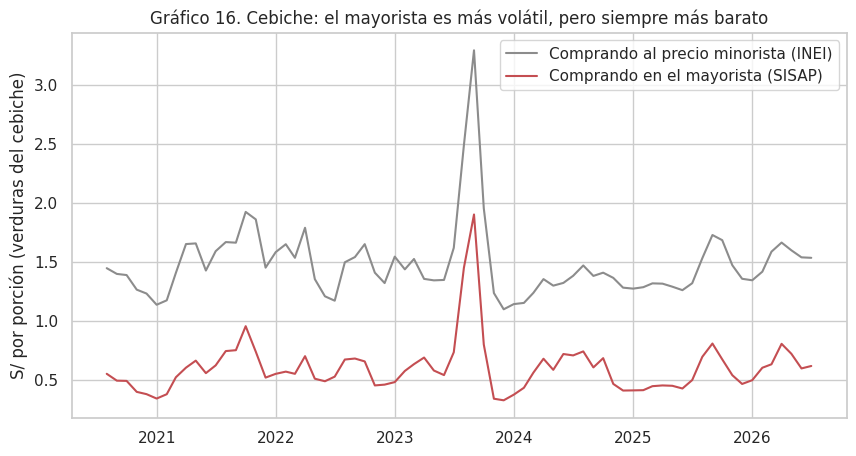

In [47]:
fig, ax = plt.subplots(figsize=(10, 5))
d = cp.loc["Cebiche"]
ax.plot(d.index, d["c_min"], label="Comprando al precio minorista (INEI)", color="#8C8C8C")
ax.plot(d.index, d["c_may"], label="Comprando en el mayorista (SISAP)", color="#C44E52")
ax.set_ylabel("S/ por porción (verduras del cebiche)")
ax.set_title("Gráfico 16. Cebiche: el mayorista es más volátil, pero siempre más barato")
ax.legend(); plt.show()

**Lectura — el trade-off del mayorista:**
- **Solo un tercio de cada alza mayorista llega al consumidor ese mes** (traslado ~30% al subir y ~34% al bajar). No hay asimetría:
  el minorista no "sube rápido y baja lento", simplemente **amortigua**. Por eso el precio mayorista es **2.4 veces más volátil** que el
  minorista (en olluco, 3.3 veces).
- Consecuencia para el restaurante: comprar en el mayorista ahorra mucho, pero **expone a la volatilidad completa**. El minorista cobra
  ~2.4 veces más a cambio de "suavizar" el precio: es como pagar un seguro carísimo.
- **Prueba de fuego:** en los 4 platos, **en ninguno de los 72 meses** de 2020 a 2026 comprar en el mayorista fue más caro que comprar
  al precio minorista de ese mismo mes. Ni siquiera en el pico del limón de sep-2023, cuando las verduras del cebiche costaron S/ 1.90
  en el mayorista (el minorista también se disparó).
- **Recomendación:** comprar en el mayorista y cubrir la volatilidad con un **colchón en la carta** (sección 12) y un **contrato para el
  limón**. Es mucho más barato que pagar el "seguro" del minorista.

## 13. Resumen: respuestas a las preguntas de la PC1 (se imprimen con los números calculados arriba)
**Recomendación final al cliente (coherente con todos los modelos):**
1. **Centralizar la compra en el Gran Mercado Mayorista** para los 8 locales. Es la palanca más grande (~S/ 276,000/año de sobrecosto evitado en el escenario)
   y en ningún mes de 2020–2026 fue más caro que el minorista (sección 12.3).
2. **Contrato de precio para el limón** (picos bruscos, 51% del costo de verduras del cebiche) y **colchón de ~S/ 0.17 por porción** en el cebiche.
3. **Vigilar SISAP cada semana**: el alza llega al consumidor en 0–1 mes (PA3) y el pronóstico solo es confiable a 1–2 semanas.
4. **Compra anticipada solo donde se validó** (cebolla roja, papa huayro y zapallo, por calendario). En el resto, stockear no ahorra.
5. **No fijar la carta con INEI**: 81% de los precios reales se alejan del dato oficial (PA4).

In [48]:
pv = lambda ins: ", ".join(ins)
print("=" * 80)
print("RESPUESTAS A LAS PREGUNTAS DECLARADAS EN LA PC1")
print("=" * 80)
print(f"\nPA1 Volatilidad (KPI1, tercio superior de CV >= {corte_cv:.0f}%): "
      f"{pv(kpi1.loc[kpi1['recomendacion_compra'] != 'Compra al día', 'insumo_estandar'])}")
print(f"    Limón el más volátil (CV {kpi1.iloc[0]['cv_pct']:.0f}%). La simulación muestra que stockear solo conviene en: "
      f"{pv(ahorro_calendario.loc[ahorro_calendario['ahorro_calendario_pct'] > 1, 'insumo_estandar'])}")
print(f"\nPA2 Margen (KPI2): mayor MBC → {kpi2.iloc[0]['insumo_estandar']} ({kpi2.iloc[0]['mbc_medio']:.0f}% del precio final); "
      f"menor → {kpi2.iloc[-1]['insumo_estandar']} ({kpi2.iloc[-1]['mbc_medio']:.0f}%)")
print(f"\nPA3 Rezago (KPI3 niveles): {(kpi3['rezago_niveles'] == 0).sum()} insumos el mismo mes, "
      f"{(kpi3['rezago_niveles'] == 1).sum()} al mes siguiente, {(kpi3['rezago_niveles'] >= 2).sum()} con 2+ meses")
print(f"\nPA4 Confiabilidad INEI (KPI4): {relev['kpi4_alerta'].mean()*100:.0f}% de los precios relevados en alerta; "
      f"{huerfana['alerta_inei'].sum()} de 16 insumos en alerta")
print(f"\nPregunta huérfana: en el punto de compra se paga en promedio {relev['brecha_vs_mayorista_pct'].mean():.0f}% "
      f"sobre el mayorista; va de {huerfana['brecha_relev_pct'].min():.0f}% ({huerfana.iloc[-1]['insumo_estandar']}) "
      f"a {huerfana['brecha_relev_pct'].max():.0f}% ({huerfana.iloc[0]['insumo_estandar']}).")
print("\n" + "=" * 80)
print("PREGUNTA CENTRAL DEL CASO: ¿con cuánta anticipación se puede anticipar un alza?")
print("=" * 80)
print(f"Modelo a 4 semanas (prueba 2026): error {m_con['MAPE_pct']:.1f}% con INEI | {m_sin['MAPE_pct']:.1f}% sin INEI | {m_naive['MAPE_pct']:.1f}% ingenuo")
print("Error según anticipación: " + " | ".join(f"{int(r.horizonte_semanas)} sem: {r.MAPE_modelo:.1f}%" for r in horizontes.itertuples()))
print(f"Estacionalidad (1-6 meses): {validacion_ts['MAPE_estacional'].mean():.1f}% vs ingenuo {validacion_ts['MAPE_ingenuo'].mean():.1f}%")
print("\n" + "=" * 80)
print("SEGMENTOS Y RECOMENDACIÓN")
print("=" * 80)
for seg, d in features.groupby("segmento"):
    print(f"   - {seg}: {', '.join(d.index)}")
print(f"Mayor oportunidad: {oportunidad.index[0]} (S/ {oportunidad.iloc[0]['ahorro_canal_soles']:,.0f}/año por comprar en mayorista)")
print(f"\nSimulación 2026: anticipar compras ahorra — alerta sin INEI {total['alerta_sin_inei']:.1f}%, "
      f"con INEI {total['alerta_con_inei']:.1f}%, techo con información perfecta {total['info_perfecta']:.1f}%")
print(f"Costo por plato: el cebiche llegó a {resumen_plato.loc['Cebiche', 'veces_max_vs_mediana']:.1f} veces su costo normal; "
      f"colchón sugerido S/ {resumen_plato.loc['Cebiche', 'colchon_sugerido']:.2f} por porción")
print(f"Escenario cadena (8 locales): CUÁNDO comprar ahorra S/ {esc['ahorro_estrategia_soles'].sum():,.0f}/año; "
      f"DÓNDE comprar (mayorista vs minorista) S/ {esc['ahorro_canal_soles'].sum():,.0f}/año")

RESPUESTAS A LAS PREGUNTAS DECLARADAS EN LA PC1

PA1 Volatilidad (KPI1, tercio superior de CV >= 44%): limon, ajo, camote_amarillo, olluco, cebolla_roja, apio
    Limón el más volátil (CV 68%). La simulación muestra que stockear solo conviene en: cebolla_roja, papa_huayro, zapallo_macre

PA2 Margen (KPI2): mayor MBC → zanahoria (69% del precio final); menor → apio (28%)

PA3 Rezago (KPI3 niveles): 12 insumos el mismo mes, 4 al mes siguiente, 0 con 2+ meses

PA4 Confiabilidad INEI (KPI4): 81% de los precios relevados en alerta; 12 de 16 insumos en alerta

Pregunta huérfana: en el punto de compra se paga en promedio 140% sobre el mayorista; va de -6% (apio) a 354% (limon).

PREGUNTA CENTRAL DEL CASO: ¿con cuánta anticipación se puede anticipar un alza?
Modelo a 4 semanas (prueba 2026): error 19.1% con INEI | 20.3% sin INEI | 19.8% ingenuo
Error según anticipación: 1 sem: 9.7% | 2 sem: 14.9% | 4 sem: 19.1% | 8 sem: 23.7%
Estacionalidad (1-6 meses): 24.4% vs ingenuo 26.2%

SEGMENTOS Y RECO

## 14. Exportación: tablas para Power BI y datos limpios
Los archivos `pbi_*` son tablas para el dashboard y los `limpio_*` son los datos limpios que se entregan junto con los crudos.
Se descargan desde el panel de archivos de Colab.

In [49]:
tabla_insumos = (kpi1.set_index("insumo_estandar")[["precio_medio", "cv_pct", "recomendacion_compra"]]
                 .join(kpi2.set_index("insumo_estandar")[["mbc_medio"]])
                 .join(kpi3.set_index("insumo_estandar")[["rezago_meses", "corr_max", "traslado"]])
                 .join(features[["alza_p90_4sem", "amplitud_estacional", "segmento"]])
                 .join(error_insumo[["error_modelo_pct", "error_ingenuo_pct"]])
                 .join(huerfana.set_index("insumo_estandar")[["brecha_relev_pct", "brecha_inei_ago26_pct", "kpi4_dif_pct", "alerta_inei"]])
                 .reset_index())
tabla_insumos["priorizado"] = tabla_insumos["insumo_estandar"].isin(SEIS)

exportar = {
    "pbi_insumos_kpis.csv": tabla_insumos,
    "pbi_precio_diario.csv": sisap16[["fecha", "insumo_estandar", "precio_soles_kg"]],
    "pbi_panel_mensual.csv": mensual[["insumo_estandar", "fecha_mes", "precio_mayorista_mes", "precio_minorista_inei", "mbc_pct"]],
    "pbi_calendario_compra.csv": calendario,
    "pbi_pronostico_mensual.csv": pronostico_mensual,
    "pbi_pronostico_4sem_2026.csv": eval4,
    "pbi_relevamiento.csv": relev,
    "pbi_ahorro_simulacion.csv": ahorro_alerta.merge(ahorro_calendario, on="insumo_estandar", how="left"),
    "pbi_costo_plato_mensual.csv": costo_plato,
    "pbi_costo_plato_resumen.csv": resumen_plato.reset_index(),
    "pbi_escenario_cadena.csv": esc.reset_index(),
}
# Datos limpios (entregable obligatorio: datos crudos y limpios)
exportar.update({
    "limpio_sisap_16insumos.csv": sisap16[["fecha", "producto", "insumo_estandar", "unidad_medida", "equiv_kg", "precio_hoy", "precio_soles_kg"]],
    "limpio_inei_16insumos.csv": inei[["producto_inei", "insumo_estandar", "año_mes", "precio_minorista_inei"]],
    "limpio_relevamiento.csv": relev[["fecha", "insumo_estandar", "establecimiento", "distrito", "precio_soles"]],
    "limpio_panel_sisap_inei.csv": panel[["fecha", "insumo_estandar", "precio_soles_kg", "precio_minorista_inei", "brecha_pct", "mbc_pct"]],
})
for nombre, tabla in exportar.items():
    tabla.to_csv(nombre, index=False, encoding="utf-8-sig")
    print(f"{nombre:<30} {len(tabla):>6,} filas")

pbi_insumos_kpis.csv               16 filas
pbi_precio_diario.csv          24,260 filas
pbi_panel_mensual.csv           1,168 filas
pbi_calendario_compra.csv         192 filas
pbi_pronostico_mensual.csv         80 filas
pbi_pronostico_4sem_2026.csv      448 filas
pbi_relevamiento.csv              147 filas
pbi_ahorro_simulacion.csv          16 filas
pbi_costo_plato_mensual.csv       292 filas
pbi_costo_plato_resumen.csv         4 filas
pbi_escenario_cadena.csv           10 filas
limpio_sisap_16insumos.csv     24,260 filas
limpio_inei_16insumos.csv       1,168 filas
limpio_relevamiento.csv           147 filas
limpio_panel_sisap_inei.csv    24,260 filas
